# Implementación final
## Ablación del entrelazamiento en una QCNN de 6 qubits con pocos datos

Benjamín Cárdenas · Computación Cuántica (INF-465) · Departamento de Informática, UTFSM · noviembre de 2026

Este notebook es el informe final de la implementación. Todo el código se ejecuta de arriba abajo. Los entrenamientos, las simulaciones ruidosas y los conteos del hardware de IBM se guardan en `resultados/`; con `RECALCULAR = False` el notebook los lee y no vuelve a calcular, y con `EJECUTAR_IBM = False` (sección 11) no se conecta a IBM Quantum. Recalcular todo toma alrededor de una hora en un computador personal.

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Devilman33/qcnn-ablacion-entrelazamiento/blob/main/Implementacion_Final_QCNN.ipynb)

**En Google Colab**, basta con *Entorno de ejecución → Ejecutar todas*. La celda siguiente descarga del [repositorio](https://github.com/Devilman33/qcnn-ablacion-entrelazamiento) los resultados guardados y los datos, e instala PennyLane, JAX y Qiskit (unos 2 minutos). En un computador con la carpeta completa y las librerías instaladas, no hace nada.

In [1]:
# Preparación para Colab o cualquier entorno donde el notebook se abra sin su carpeta.
import importlib.util, os, subprocess, sys
from pathlib import Path

REPO = "https://github.com/Devilman33/qcnn-ablacion-entrelazamiento.git"
if not Path("resultados").exists():
    if not Path("qcnn-ablacion-entrelazamiento").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO], check=True)
    os.chdir("qcnn-ablacion-entrelazamiento")
if any(importlib.util.find_spec(m) is None for m in ("pennylane", "jax", "optax", "qiskit", "qiskit_aer", "qiskit_ibm_runtime")):
    from importlib.metadata import version
    numpy_antes = version("numpy")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    if "numpy" in sys.modules and version("numpy") != numpy_antes:
        print("La instalación cambió la versión de NumPy: reinicia la sesión (Entorno de ejecución → Reiniciar sesión) "
              "y vuelve a ejecutar todo. Esta celda no volverá a instalar nada.")
print("Carpeta de trabajo:", Path.cwd())

Carpeta de trabajo: C:\Users\benja\OneDrive\Desktop\QC\entrega 5


## Resumen

**Pregunta.** ¿Qué aporta el entrelazamiento a una red convolucional cuántica (QCNN) pequeña que aprende a clasificar imágenes con pocos ejemplos?

**Implementación.** La QCNN de 6 qubits y 45 parámetros de Anthony et al. (2026), con el código del tutorial de PennyLane como referencia, porque los autores no publicaron el suyo. La entreno en PennyLane con JAX y la escribo también en Qiskit; las dos versiones dan la misma probabilidad hasta $10^{-13}$. Comparo la QCNN con tres controles sin compuertas entrelazantes y con dos regresiones logísticas, sobre las mismas particiones.

**Resultados.**

- **Replicación cerrada.** En simulación exacta la QCNN llega a 95% con 2 imágenes de los dígitos 0 y 1; Anthony et al. reportan 75%. Simulando su backend (ruido de FakeKyiv calibrado en Aer, 4 000 *shots* y gradientes por diferencias finitas) obtengo 81.5% con 2 imágenes, 67.5% con 5 y una pérdida de entrenamiento de 0.55 a 0.60, como la de su registro (0.53 a 0.57). Ninguno de los tres efectos produce la caída por separado.
- **El entrelazamiento no es necesario.** En 4 pares de dígitos, 7 tamaños de entrenamiento (2 a 200 imágenes) y 20 repeticiones, un control sin compuertas entrelazantes que mide los dos qubits finales (LOCC-2) nunca queda significativamente bajo la QCNN (corrección de Holm sobre 84 comparaciones). Con 200 imágenes obtiene 97.4% a 99.4%; la QCNN, 95.9% a 99.1%.
- **El diseño del control decide la conclusión.** El control del avance, que comprime los dos qubits finales en uno, queda 5 a 7 puntos bajo la QCNN en los dígitos 2 y 3 y 3 y 8, y no logra ajustar ni su entrenamiento. Con ese control la conclusión habría sido la contraria.
- **La exactitud no sigue al entrelazamiento.** Atenuar las compuertas Ising por $\lambda$ muestra un umbral cerca de 0: con $\lambda = 0.25$ la QCNN ya rinde como con $\lambda = 1$, aunque genera entre la mitad y dos tercios del entrelazamiento. Entre repeticiones, el entrelazamiento generado no se correlaciona con la exactitud.
- **En hardware real.** En ibm_fez (dígitos 3 y 5, $N = 40$), la QCNN acierta 99 de 100 imágenes, igual que en simulación exacta, y el LOCC-2 también. En la tabla de una repetición ejecutada en ibm_kingston (4 pares, $N = 20$ y 200, 3 200 circuitos), la QCNN pierde 2.6 puntos en promedio y queda 0.8 puntos sobre el LOCC-2, una diferencia que una repetición no permite distinguir. Los controles con salida logística pierden más (5 y 9 puntos), porque el ruido encoge sus valores esperados y el sesgo de la logística pesa más. En total usé 565 de los 600 segundos de QPU del plan gratuito.
- **No hay ventaja cuántica.** Una regresión logística sobre los píxeles es el mejor modelo, o empata con el mejor, desde 20 imágenes.

## 1. Estado del proyecto

| Entrega | Contenido | Estado |
|---|---|---|
| 1 | Problema clásico (clasificación de imágenes con MLP y CNN) y su estado del arte | Entregada |
| 2 | Primera versión del estado del arte cuántico: 42 trabajos, brechas y propuesta | Entregada |
| 3 | Segunda versión: 45 trabajos, tabla de aportes y matriz de criterios | Entregada el 27 de octubre |
| 4 | Primer avance de la implementación | Entregado el 3 de noviembre |
| 5 | Implementación final (este notebook) | 24 de noviembre |

La pregunta de investigación es qué aporta el entrelazamiento a una red convolucional cuántica (QCNN) pequeña que aprende a clasificar imágenes con pocos ejemplos.

La brecha viene de la entrega 3. No encontré una QCNN evaluada con y sin entrelazamiento, con una lectura que deje a ambas versiones ver toda la imagen, en el régimen de pocos datos y frente a modelos clásicos. El trabajo más cercano es Anthony et al. (2026), que entrenan una QCNN de 6 qubits con 2 a 80 imágenes sin quitar el entrelazamiento.

### Qué agrega esta entrega al avance

El avance terminó con seis pasos pendientes. Esta tabla dice dónde se resuelve cada uno:

| # | Pendiente del avance | Dónde | Estado |
|---|---|---|---|
| — | Implementar en Qiskit, como pide el curso | Sección 7 | Hecho: los cuatro modelos, verificados contra PennyLane |
| 1 | Cerrar la replicación de Anthony et al. con *shots* y ruido | Sección 8.2 | Hecho, con el ruido de FakeKyiv calibrado en Aer |
| 2 | Experimento final: 20 repeticiones, 4 pares, entrenamiento hasta converger | Sección 9 | Hecho: 4 pares × 7 tamaños × 20 repeticiones × 6 modelos |
| 3 | Revisar el control LOCC en 0 y 1 con una variante que lea dos qubits | Secciones 6 y 9 | Hecho: control LOCC-2 |
| 4 | Barrido continuo $\lambda \in [0, 1]$ de las compuertas Ising | Sección 10 | Hecho |
| 5 | Medir el entrelazamiento que genera la QCNN entrenada | Sección 10 | Hecho: Meyer-Wallach y entropía filas\|columnas |
| 6 | Contrastar el control local con el modelo separable de `qml-benchmarks` | — | No hecho (sección 12) |
| — | Ejecutar en un computador cuántico real | Sección 11 | Hecho en IBM Quantum: ibm_fez e ibm_kingston, inferencia, 565 s de QPU |

Las secciones 2 a 4 y 8 a 8.1 repiten, con cambios menores, la verificación del avance, para que este notebook se pueda leer solo.

## 2. ¿Liberaron su código los autores?

Busqué el 3 de noviembre de 2026 en arXiv, Zenodo, GitHub y las páginas de cada artículo. También revisé la sección de disponibilidad de datos de los PDF que tengo en `entrega 1/papers_cuanticos/`.

| Trabajo | ¿Código? | Qué hay publicado | Relevancia para este trabajo |
|---|---|---|---|
| Anthony et al. (2026), arXiv:2609.24666 | No | Solo la v1 en arXiv (21 de septiembre de 2026). En Zenodo ([10.5281/zenodo.22820877](https://zenodo.org/records/22820877), CC BY 4.0) hay únicamente resultados: los registros de entrenamiento por paso y las matrices de confusión, en CSV. El README dice: *"This deposit holds the results only [...] the training code is described in the paper."* | Es la referencia del protocolo y de los números a reproducir |
| Tutorial de PennyLane de Kottmann, Mantilla Calderón y Weber (2022, actualizado el 16 de junio de 2026) | Sí | [PennyLaneAI/demos](https://github.com/PennyLaneAI/demos), `tutorial_learning_few_data`, licencia Apache 2.0 | Misma QCNN de 6 qubits, mismos dígitos y mismos tamaños de entrenamiento. Base del código |
| Hur, Kim y Park (2022) | Sí | [takh04/QCNN](https://github.com/takh04/QCNN), Apache 2.0, en PennyLane y sin versiones fijadas | QCNN de 8 qubits sobre MNIST reducido con PCA. Es otra arquitectura, así que no sirve de referencia directa para esta QCNN; sí para las codificaciones |
| Bowles, Ahmed y Schuld (2024) | Sí | [XanaduAI/qml-benchmarks](https://github.com/XanaduAI/qml-benchmarks), Apache 2.0, en PennyLane y JAX | Trae un modelo separable (`separable.py`) que sirve de referencia para los controles |
| Basilewitsch et al. (2025) | No | *"The data used in this study is available upon reasonable request"* | Solo comparación |
| Bermejo et al. (2026) | No encontré | Sin enlace en el artículo ni en la web | Solo comparación |
| Kashif y Al-Kuwari (2023) | No encontré | Sin enlace en el artículo ni en la web | Solo comparación |
| Nakhl, Quella y Usman (2024) | No encontré | Sin enlace en el artículo ni en la web | Solo comparación |

### Decisión: sigo con Anthony et al. como referencia y uso el tutorial de PennyLane como base del código

Que Anthony et al. no hayan publicado su código no obliga a cambiar de referencia. Su QCNN es, en la práctica, la del tutorial de PennyLane, y lo compruebo de cuatro maneras:

1. Los bloques son los mismos. En las dos, la convolución tiene $U3$ previas (solo en la primera capa), luego $R_{XX}R_{YY}R_{ZZ}$ y luego $U3$ posteriores, con ángulos compartidos entre pares. El *pooling* mide el qubit impar y aplica una $U3$ condicionada al vecino. La capa densa es un `ArbitraryUnitary` de 15 parámetros sobre los dos qubits restantes, y el artículo dice que la construyeron con el `ArbitraryUnitary` de PennyLane.
2. Las cifras del circuito coinciden. Mi implementación da 51 operaciones (contando la codificación, las 4 mediciones intermedias y las 4 rotaciones condicionadas), 45 parámetros y profundidad 23. El artículo reporta "51 gates, 45 parameters and a logical circuit depth of 23" sin decir qué cuenta como compuerta (sección 4.3).
3. El programa de tasa de aprendizaje es el mismo. En el registro de Zenodo, la tasa baja de 0.1 a 0.0950049 en 50 pasos, igual hasta el séptimo decimal que el `optax.cosine_decay_schedule(0.1, alpha=0.95)` del tutorial (sección 4.3).
4. El experimento es el mismo: los dígitos 0 y 1 de scikit-learn, $N \in \{2, 5, 10, 20, 40, 80\}$ y 100 imágenes de prueba.

También uso el código del tutorial como referencia ejecutable. Lo corro sin modificar y comparo con él mi implementación, primero circuito contra circuito (sección 4.4) y después entrenamiento contra entrenamiento (sección 6.1).

Sin su código no puedo reproducir el backend de Anthony et al. Ellos ejecutaron en Qiskit con el simulador ruidoso FakeKyiv, 4 000 *shots* y gradientes por diferencias finitas ($\varepsilon = 0.05$). Eso no cambia la arquitectura. Entreno con simulación exacta del vector de estado y gradientes automáticos. La sección 8.2 simula sus condiciones (FakeKyiv, 4 000 *shots* y diferencias finitas) para ver cuánto cambia el resultado por eso, y la sección 11 ejecuta los modelos entrenados en un computador cuántico de IBM.

Los CSV de Zenodo me sirven como objetivo numérico: comparo mis curvas con las suyas, paso a paso.

## 3. Entorno

El Python global del equipo (3.14) no trae PennyLane, JAX ni Qiskit. Creé un entorno aparte en `C:\Users\benja\.venvs\qc`, fuera de OneDrive para que no se sincronice. PennyLane 0.45.1 no funciona con JAX 0.12, que usa una API que PennyLane todavía no soporta, así que fijé JAX en 0.10.2. Para la entrega final agregué Qiskit 2.6, Qiskit Aer 0.18 y Qiskit IBM Runtime 0.52. Las versiones exactas están en `requirements.txt`, junto a este notebook.

```
python -m venv C:\Users\benja\.venvs\qc
C:\Users\benja\.venvs\qc\Scripts\pip install -r requirements.txt
```

In [2]:
import platform, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import jax
import jax.numpy as jnp
import optax
jax.config.update("jax_platform_name", "cpu")
jax.config.update("jax_enable_x64", True)

import pennylane as qml
import sklearn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

RAIZ = Path.cwd()
DIR_RES = RAIZ / "resultados"
DIR_RES.mkdir(exist_ok=True)
DIR_ZEN = RAIZ / "datos_anthony_zenodo" / "Results data"
RECALCULAR = False   # True: vuelve a entrenar todo aunque existan los CSV

print(f"Python {platform.python_version()} | PennyLane {qml.__version__} | JAX {jax.__version__} | "
      f"Optax {optax.__version__} | scikit-learn {sklearn.__version__}")

Python 3.14.7 | PennyLane 0.45.1 | JAX 0.10.2 | Optax 0.2.8 | scikit-learn 1.9.1


In [3]:
# Estilo de las figuras. Colores fijos por modelo (paleta validada para daltonismo);
# como tres de ellos tienen poco contraste con el fondo, cada figura va con su tabla.
COLOR = {
    "QCNN": "#2a78d6",
    "Control LOCC": "#eb6834",
    "Control local": "#1baf7a",
    "Regresión logística": "#eda100",
    "Lineal sobre un cuerpo": "#e87ba4",
    "Control LOCC-2": "#008300",
}
MARCA = {"QCNN": "o", "Control LOCC": "s", "Control local": "^", "Regresión logística": "D", "Lineal sobre un cuerpo": "v",
         "Control LOCC-2": "P"}
GRIS, GRIS_OSC = "#898781", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": GRIS_OSC, "ytick.color": GRIS_OSC, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "lines.markersize": 7, "font.size": 10, "legend.frameon": False,
})


def ic95(x):
    # Media e intervalo de confianza de 95% con t de Student, como en Anthony et al.
    x = np.asarray(x, float)
    if len(x) < 2:
        return x.mean(), 0.0
    return x.mean(), stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))

## 4. Datos y QCNN de referencia

### 4.1 Datos

Uso los dígitos de 8×8 de scikit-learn. Cada imagen se aplana en orden de filas a 64 valores, se normaliza con la norma $\ell_2$ y se codifica en las amplitudes de 6 qubits:

$$|\psi(x)\rangle = \sum_{k=0}^{63} \frac{x_k}{\lVert x\rVert_2}\,|k\rangle .$$

En PennyLane el qubit 0 es el bit más significativo del índice $k$. Por eso los qubits 0 a 2 indican la fila del píxel y los qubits 3 a 5 la columna.

Las particiones siguen el protocolo de Anthony et al.:

- En cada repetición se sacan $N$ imágenes de entrenamiento con las clases balanceadas y 100 de prueba entre las restantes.
- La semilla depende solo de $(N, \text{repetición})$, de modo que todos los modelos ven las mismas imágenes: las comparaciones son pareadas.
- La clase positiva es el segundo dígito del par.

Uso cuatro pares. El 0 y 1 es el de Anthony et al. y queda como caso en que no espero diferencia, porque la información de un cuerpo ya da 98% con 20 imágenes. El 3 y 5 es el del piloto. El 2 y 3 y el 3 y 8 se agregan en esta entrega: en la entrega 3 eran, junto al 3 y 5, los pares con más margen entre la información de un cuerpo y la de dos.

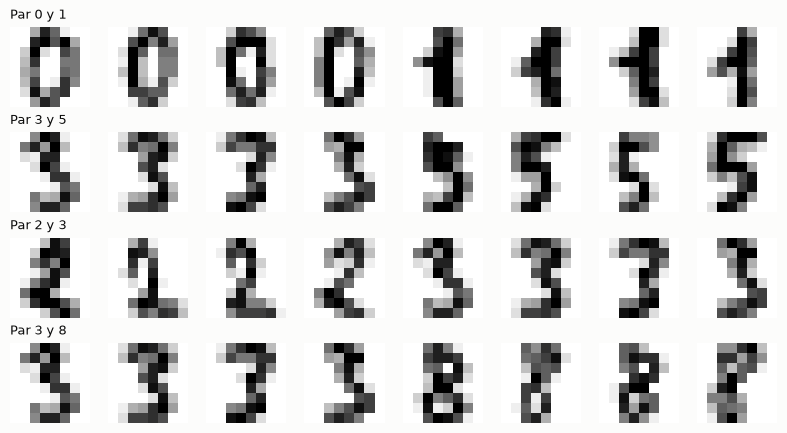

Par (0, 1): 360 imágenes (178 del 0, 182 del 1)
Par (3, 5): 365 imágenes (183 del 3, 182 del 5)
Par (2, 3): 360 imágenes (177 del 2, 183 del 3)
Par (3, 8): 357 imágenes (183 del 3, 174 del 8)


In [4]:
DIGITOS = load_digits()


def cargar_par(a, b):
    m = (DIGITOS.target == a) | (DIGITOS.target == b)
    X = DIGITOS.data[m] / np.linalg.norm(DIGITOS.data[m], axis=1, keepdims=True)
    y = (DIGITOS.target[m] == b).astype(float)
    return X, y


def particion(X, y, n, rep, n_test=100):
    return train_test_split(X, y, train_size=n, test_size=n_test, stratify=y, random_state=1000 * rep + n)


PARES = [(0, 1), (3, 5), (2, 3), (3, 8)]
fig, axes = plt.subplots(len(PARES), 8, figsize=(8, 4.4))
for fila, par in enumerate(PARES):
    X, y = cargar_par(*par)
    idx = np.r_[np.where(y == 0)[0][:4], np.where(y == 1)[0][:4]]
    for ax, i in zip(axes[fila], idx):
        ax.imshow(X[i].reshape(8, 8), cmap="gray_r"); ax.axis("off")
    axes[fila, 0].set_title(f"Par {par[0]} y {par[1]}", loc="left", fontsize=9)
plt.tight_layout(); plt.show()
for par in PARES:
    X, y = cargar_par(*par)
    print(f"Par {par}: {len(y)} imágenes ({int((y == 0).sum())} del {par[0]}, {int(y.sum())} del {par[1]})")

### 4.2 La QCNN

La arquitectura es la de la Figura 4 de Anthony et al. El código está adaptado del tutorial de PennyLane (Apache 2.0). Cambié una cosa: el tutorial guarda los pesos en una matriz de $18\times 2$, y la segunda capa deja 6 de ellos sin usar, por lo que tiene 51 pesos nominales. Aquí uso un vector de exactamente 45 parámetros, ordenados como $\theta_0,\dots,\theta_{44}$ en la figura del artículo:

| Bloque | Parámetros | Índices |
|---|---|---|
| Convolución 1: $U3$ previas, $R_{XX}R_{YY}R_{ZZ}$, $U3$ posteriores | 15 | $\theta_0$ a $\theta_{14}$ |
| *Pooling* 1: $U3$ condicionada a la medición | 3 | $\theta_{15}$ a $\theta_{17}$ |
| Convolución 2: sin $U3$ previas | 9 | $\theta_{18}$ a $\theta_{26}$ |
| *Pooling* 2 | 3 | $\theta_{27}$ a $\theta_{29}$ |
| Capa densa $SU(4)$ sobre los qubits 0 y 4 | 15 | $\theta_{30}$ a $\theta_{44}$ |

La salida es $p(x) = P(q_0 = 1)$, la probabilidad de la clase positiva, y la predicción es $p > 0.5$.

PennyLane simula las mediciones intermedias con el principio de medición diferida. La probabilidad es exacta y el circuito se puede derivar de forma automática.

In [5]:
NQ = 6
DEV = qml.device("default.qubit", wires=NQ)


def capa_conv(w, wires, primera, escala=1.0):
    # Barrido par e impar de pares vecinos con el mismo kernel. w tiene 15 ángulos (primera capa) o 9.
    # escala multiplica los ángulos Ising: 0 los quita (controles) y entre 0 y 1 los atenúa (sección 10).
    k = 6 if primera else 0
    for paridad in (0, 1):
        for i, a in enumerate(wires):
            if i % 2 == paridad and i < len(wires) - 1:
                b = wires[i + 1]
                if primera and paridad == 0:
                    qml.U3(*w[0:3], wires=a)
                    qml.U3(*w[3:6], wires=b)
                if escala != 0:
                    qml.IsingXX(escala * w[k], wires=[a, b])
                    qml.IsingYY(escala * w[k + 1], wires=[a, b])
                    qml.IsingZZ(escala * w[k + 2], wires=[a, b])
                qml.U3(*w[k + 3:k + 6], wires=a)
                qml.U3(*w[k + 6:k + 9], wires=b)


def capa_pooling(w, wires):
    # Mide cada qubit impar y, si sale 1, aplica una U3 (ángulos compartidos) al vecino.
    for i, a in enumerate(wires):
        if i % 2 == 1:
            m = qml.measure(a)
            qml.cond(m, qml.U3)(*w, wires=wires[i - 1])


@qml.qnode(DEV)
def circuito_qcnn(th, x):
    qml.AmplitudeEmbedding(x, wires=range(NQ))
    w = list(range(NQ))
    capa_conv(th[0:15], w, primera=True)
    capa_pooling(th[15:18], w)
    w = w[::2]                                   # quedan 0, 2, 4
    capa_conv(th[18:27], w, primera=False)
    capa_pooling(th[27:30], w)
    w = w[::2]                                   # quedan 0, 4
    qml.ArbitraryUnitary(th[30:45], wires=w)
    return qml.probs(wires=0)


def p_qcnn(th, x):
    return circuito_qcnn(th, x)[1]

### 4.3 Verificación contra el artículo

Comparo mi circuito con las cifras que da el artículo y con el programa de tasa de aprendizaje que aparece en sus registros de Zenodo.

In [6]:
x0 = cargar_par(0, 1)[0][0]
spec = qml.specs(circuito_qcnn)(jnp.zeros(45), x0)["resources"]
tabla = pd.DataFrame({
    "Anthony et al. (2026)": [6, 51, 45, 23],
    "Esta implementación": [spec.num_allocs, spec.num_gates, 45, spec.depth],
}, index=["Qubits", "Operaciones del circuito", "Parámetros entrenables", "Profundidad lógica"])
display(tabla)
print("Tipos de compuerta:", dict(spec.gate_types))

,Anthony et al. (2026),Esta implementación
Qubits,6,6
Operaciones del circuito,51,51
Parámetros entrenables,45,45
Profundidad lógica,23,23


Tipos de compuerta: {'AmplitudeEmbedding': 1, 'U3': 20, 'IsingXX': 7, 'IsingYY': 7, 'IsingZZ': 7, 'MidMeasureMP': 4, 'Conditional(U3)': 4, 'ArbitraryUnitary': 1}


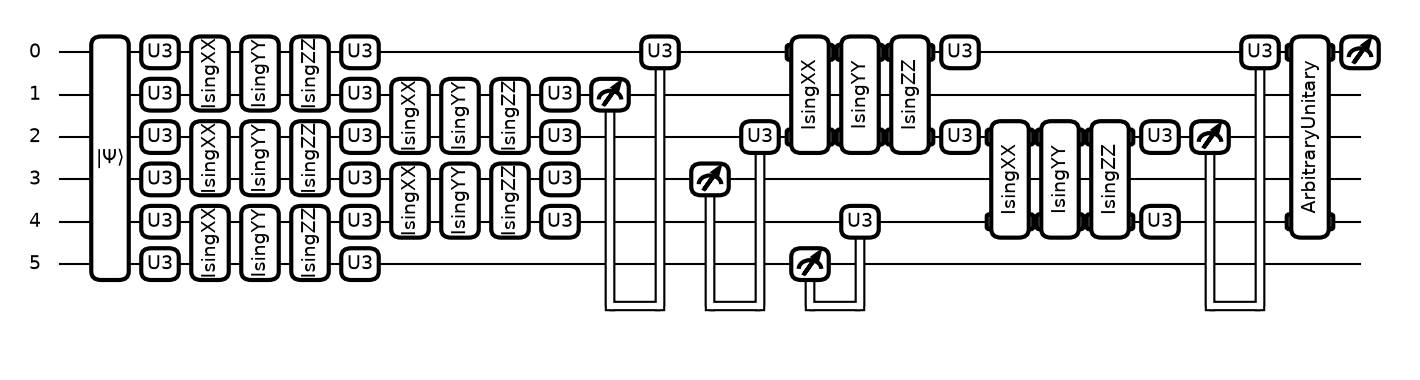

In [7]:
fig, ax = qml.draw_mpl(circuito_qcnn, style="black_white", decimals=None)(
    jnp.arange(45.0), x0)
fig.set_size_inches(14, 3.6)
plt.show()

In [8]:
log_anthony = pd.read_csv(DIR_ZEN / "Digits QCNN" /
                          "complete_results_dynamic_circuit_corrected_Adam_denselayer12_digits_postdebug.csv")
programa = optax.cosine_decay_schedule(0.1, decay_steps=50, alpha=0.95)
lr_zenodo = log_anthony.query("n_train == 2 and rep == 0").sort_values("step").lr.to_numpy()
lr_optax = np.array([programa(i) for i in range(50)])
print(f"Pasos por repetición en Zenodo: {log_anthony.step.max()}")
print(f"Tasa en el paso 1 y en el 50 (Zenodo): {lr_zenodo[0]:.7f}, {lr_zenodo[-1]:.7f}")
print(f"Tasa en el paso 1 y en el 50 (optax):  {lr_optax[0]:.7f}, {lr_optax[-1]:.7f}")
print(f"Diferencia máxima en los 50 pasos: {np.abs(lr_zenodo - lr_optax).max():.1e}")

Pasos por repetición en Zenodo: 50
Tasa en el paso 1 y en el 50 (Zenodo): 0.1000000, 0.0950049
Tasa en el paso 1 y en el 50 (optax):  0.1000000, 0.0950049
Diferencia máxima en los 50 pasos: 0.0e+00


### 4.4 Referencia con código abierto: el tutorial de PennyLane, sin modificar

Las comparaciones anteriores son contra cifras publicadas. Para tener una referencia que se pueda ejecutar, uso el código original del tutorial de PennyLane. Bajé `demo.py` del repositorio [PennyLaneAI/demos](https://github.com/PennyLaneAI/demos/tree/b715a7e06be70ecfb8d1940b84196c4eb2384bda/demonstrations_v2/tutorial_learning_few_data), fijado al commit `b715a7e` del 17 de junio de 2026. Está en `referencia_pennylane/` junto con su licencia (Apache 2.0).

El archivo define las funciones y al final entrena y grafica. Para no correr esa parte, lo leo con `ast` y ejecuto solo:

- las importaciones, salvo `seaborn`, que se usa únicamente para graficar;
- las definiciones de funciones;
- las constantes (`seed`, `rng`, `num_wires`, `device`, `value_and_grad`, `n_test`, `n_epochs`, `n_reps`, `train_sizes`),

sin cambiar ninguna línea.

El primer chequeo es de equivalencia. Con los mismos parámetros, mi circuito y el del tutorial deben dar la misma probabilidad para cada imagen. Para comparar, paso mi vector de 45 parámetros a la matriz de $18\times 2$ del tutorial más los 15 de su capa densa. También compruebo que los 6 pesos que la segunda capa del tutorial no usa no cambian la salida, lo que explica por qué sus 51 pesos nominales son 45.

In [9]:
import ast

DIR_TUT = RAIZ / "referencia_pennylane"
arbol = ast.parse((DIR_TUT / "demo.py").read_text(encoding="utf-8"))
CONSTANTES = {"seed", "rng", "num_wires", "device", "value_and_grad", "n_test", "n_epochs", "n_reps", "train_sizes"}


def se_ejecuta(nodo):
    if isinstance(nodo, (ast.Import, ast.ImportFrom)):
        return all(a.name != "seaborn" for a in nodo.names)
    if isinstance(nodo, ast.FunctionDef):
        return True
    if isinstance(nodo, ast.Assign):
        return all(isinstance(t, ast.Name) and t.id in CONSTANTES for t in nodo.targets)
    if isinstance(nodo, ast.Expr) and isinstance(nodo.value, ast.Call):
        return ast.unparse(nodo.value.func) == "jax.config.update"
    return False


ejecutadas = [n for n in arbol.body if se_ejecuta(n)]
TUT = {}
exec(compile(ast.Module(body=ejecutadas, type_ignores=[]), str(DIR_TUT / "demo.py"), "exec"), TUT)
print(f"demo.py: {len(ejecutadas)} sentencias ejecutadas tal cual, {len(arbol.body) - len(ejecutadas)} omitidas "
      "(texto, gráficos y el bucle de entrenamiento final)")
print("Funciones del tutorial:", ", ".join(n.name for n in ejecutadas if isinstance(n, ast.FunctionDef)))
print(f"Configuración del tutorial: n_test={TUT['n_test']}, n_epochs={TUT['n_epochs']}, "
      f"n_reps={TUT['n_reps']}, train_sizes={TUT['train_sizes']}")

demo.py: 33 sentencias ejecutadas tal cual, 44 omitidas (texto, gráficos y el bucle de entrenamiento final)
Funciones del tutorial: convolutional_layer, pooling_layer, conv_and_pooling, dense_layer, conv_net, load_digits_data, compute_out, compute_accuracy, compute_cost, init_weights, train_qcnn, run_iterations
Configuración del tutorial: n_test=100, n_epochs=100, n_reps=100, train_sizes=[2, 5, 10, 20, 40, 80]


In [10]:
def a_pesos_tutorial(th, relleno):
    # Mis 45 parámetros -> matriz (18, 2) y vector de 15 del tutorial.
    W = np.zeros((18, 2))
    W[:, 0] = th[0:18]
    W[0:6, 1] = relleno            # pesos que la segunda capa del tutorial no usa
    W[6:15, 1] = th[18:27]
    W[15:18, 1] = th[27:30]
    return jnp.array(W), jnp.array(th[30:45])


X01, y01 = cargar_par(0, 1)
p_mia = jax.jit(jax.vmap(p_qcnn, in_axes=(None, 0)))
p_tut = jax.jit(jax.vmap(lambda W, L, x: TUT["conv_net"](W, L, x)[1], in_axes=(None, None, 0)))

filas = []
for s in range(5):
    r = np.random.default_rng(100 + s)
    th = r.normal(size=45)
    W1, L = a_pesos_tutorial(th, r.normal(size=6))
    W2, _ = a_pesos_tutorial(th, r.normal(size=6))
    a, b, c = p_mia(jnp.array(th), X01), p_tut(W1, L, X01), p_tut(W2, L, X01)
    filas.append({"Parámetros al azar": s,
                  "Máx |p_mía − p_tutorial| (360 imágenes)": f"{float(jnp.abs(a - b).max()):.1e}",
                  "Máx cambio al variar los 6 pesos sin uso": f"{float(jnp.abs(b - c).max()):.1e}",
                  "Rango de p": f"{float(a.min()):.3f} – {float(a.max()):.3f}"})
display(pd.DataFrame(filas).set_index("Parámetros al azar"))

,Máx |p_mía − p_tutorial| (360 imágenes),Máx cambio al variar los 6 pesos sin uso,Rango de p
Parámetros al azar,,,
0,7.8e-16,0.0e+00,0.414 – 0.671
1,7.8e-16,0.0e+00,0.463 – 0.653
2,1.0e-15,0.0e+00,0.489 – 0.700
3,8.9e-16,0.0e+00,0.410 – 0.653
4,5.6e-16,0.0e+00,0.409 – 0.637


## 5. Entrenamiento

Sigo el protocolo de Anthony et al. en todo lo que el artículo especifica:

- Pérdida: entropía cruzada binaria (el tutorial usa $1 - \bar p_{\text{correcta}}$).
- Optimizador: Adam con tasa inicial 0.1 y decaimiento coseno (`alpha = 0.95`), con el lote completo.
- Pesos iniciales con distribución normal estándar, como en el tutorial. Los sesgos de las salidas clásicas parten en 0.
- El error de generalización es $\mathrm{gen} = \hat R_{\text{prueba}} - \hat R_{\text{entrenamiento}}$ en la última época.

Hay dos funciones de entrenamiento con el mismo algoritmo. `entrenar` procesa una repetición y registra cada época; la uso en la replicación, que compara curvas época por época con Anthony et al. `entrenar_lote` entrena todas las repeticiones de un mismo tamaño $N$ a la vez con `jax.vmap` y recorre las épocas con `jax.lax.scan`, dentro de una sola función compilada. Es la que hace posible el experimento final: 20 repeticiones de 200 épocas con $N = 200$ tardan unos 45 segundos por modelo.

In [11]:
MODELOS = {}   # nombre -> p(θ, x) vectorizada, número de parámetros, inicialización, pérdidas


def registrar(nombre, p, n_param, n_clasicos=0):
    pv = jax.jit(jax.vmap(p, in_axes=(None, 0)))

    def bce(th, X, y):
        q = jnp.clip(pv(th, X), 1e-9, 1 - 1e-9)
        return -jnp.mean(y * jnp.log(q) + (1 - y) * jnp.log(1 - q))

    def uno_menos_p(th, X, y):
        # Pérdida del tutorial de PennyLane: 1 − probabilidad media de la clase correcta.
        q = pv(th, X)
        return 1.0 - jnp.mean(y * q + (1 - y) * (1 - q))

    def init(semilla):
        th = np.random.default_rng(semilla).normal(size=n_param)
        if n_clasicos:                       # el sesgo de la salida clásica (último parámetro) parte en 0
            th[-1] = 0.0
        return jnp.array(th)

    MODELOS[nombre] = dict(p=p, pv=pv, n=n_param, init=init, bce=bce,
                           perdida={"bce": jax.jit(bce), "1-p": jax.jit(uno_menos_p)},
                           vg={"bce": jax.jit(jax.value_and_grad(bce)),
                               "1-p": jax.jit(jax.value_and_grad(uno_menos_p))})


def entrenar(nombre, Xtr, ytr, Xte, yte, semilla, epocas=50, lr=0.1, registro=False, perdida="bce"):
    M = MODELOS[nombre]
    costo, vg = M["perdida"][perdida], M["vg"][perdida]
    th = M["init"](semilla)
    opt = optax.adam(optax.cosine_decay_schedule(lr, epocas, alpha=0.95))
    estado = opt.init(th)
    Xtr, ytr, Xte, yte = map(jnp.asarray, (Xtr, ytr, Xte, yte))
    filas, perdidas = [], []
    for ep in range(1, epocas + 1):
        l, g = vg(th, Xtr, ytr)
        upd, estado = opt.update(g, estado)
        th = optax.apply_updates(th, upd)
        perdidas.append(float(l))
        if registro or ep == epocas:
            ptr, pte = M["pv"](th, Xtr), M["pv"](th, Xte)
            filas.append(dict(step=ep, train_cost=float(costo(th, Xtr, ytr)),
                              test_cost=float(costo(th, Xte, yte)),
                              train_acc=float(jnp.mean((ptr > 0.5) == ytr)),
                              test_acc=float(jnp.mean((pte > 0.5) == yte))))
    return filas, perdidas, th


def entrenar_lote(nombre, Xtr, ytr, semillas, epocas, lr=0.1):
    # Xtr: (R, N, 64), ytr: (R, N). Entrena las R repeticiones en paralelo; mismo algoritmo que entrenar().
    M = MODELOS[nombre]
    clave = ("lote", epocas, lr)
    if clave not in M:
        opt = optax.adam(optax.cosine_decay_schedule(lr, epocas, alpha=0.95))
        vg = jax.value_and_grad(M["bce"])

        def una(th0, X, y):
            def paso(c, _):
                th, st = c
                l, g = vg(th, X, y)
                u, st = opt.update(g, st)
                return (optax.apply_updates(th, u), st), l
            (th, _), ls = jax.lax.scan(paso, (th0, opt.init(th0)), None, length=epocas)
            return th, ls
        M[clave] = jax.jit(jax.vmap(una))
    th0 = jnp.stack([M["init"](s) for s in semillas])
    return M[clave](th0, jnp.asarray(Xtr), jnp.asarray(ytr))


def evaluar_lote(nombre, th, X, y):
    # th: (R, P), X: (R, n, 64). Devuelve exactitud y entropía cruzada por repetición.
    M = MODELOS[nombre]
    if "ev" not in M:
        M["ev"] = jax.jit(jax.vmap(lambda t, X, y: (jnp.mean((M["pv"](t, X) > 0.5) == y), M["bce"](t, X, y))))
    acc, l = M["ev"](th, jnp.asarray(X), jnp.asarray(y))
    return np.asarray(acc), np.asarray(l)


def particiones_lote(par, n, reps):
    X, y = cargar_par(*par)
    P = [particion(X, y, n, rep) for rep in range(reps)]
    return [np.stack([p[i] for p in P]) for i in range(4)]          # Xtr, Xte, ytr, yte con forma (R, ...)


registrar("QCNN", p_qcnn, 45)

In [12]:
def caracteristicas_un_cuerpo(X):
    # <X_i> y <Z_i> de cada qubit para el estado codificado en amplitudes (<Y_i> = 0 con amplitudes reales).
    psi = X.reshape(-1, *[2] * NQ)
    feats = []
    for q in range(NQ):
        signo = np.array([1.0, -1.0]).reshape([1] + [2 if j == q else 1 for j in range(NQ)])
        feats.append((psi ** 2 * signo).reshape(len(X), -1).sum(1))                 # <Z_q>
        feats.append((psi * np.flip(psi, axis=q + 1)).reshape(len(X), -1).sum(1))   # <X_q>
    return np.stack(feats, axis=1)


def clasicos(Xtr, ytr, Xte, yte):
    # Regresión logística sobre los píxeles normalizados y sobre las 12 cantidades de un cuerpo.
    # Sin estandarizar: con N = 2 la estandarización deja cada píxel en ±1 y la exactitud cae a ~65%.
    # C = 100 porque con C = 1 el modelo colapsa a la clase mayoritaria en N = 5 (clases 2 y 3).
    out = {}
    for nombre, f in [("Regresión logística", lambda Z: Z), ("Lineal sobre un cuerpo", caracteristicas_un_cuerpo)]:
        clf = LogisticRegression(C=100.0, max_iter=5000)
        out[nombre] = clf.fit(f(Xtr), ytr).score(f(Xte), yte)
    return out

## 6. Controles sin entrelazamiento

Un control sin entrelazamiento tiene que cumplir dos condiciones. Ninguna de sus compuertas puede crear entrelazamiento entre qubits, y la salida tiene que poder depender de los seis qubits. Si no cumple la segunda, el control empeora porque no ve parte de la imagen y la caída se le atribuye por error al entrelazamiento. Eso le pasó al piloto de la entrega 3, que leía un solo qubit sin compuertas que lo conectaran con los demás y caía a 72%.

Los tres controles conservan la codificación en amplitudes, la pérdida, el optimizador, las épocas y las particiones de la QCNN. La imagen codificada ya viene entrelazada (la sección 10 lo mide), pero ningún control agrega entrelazamiento.

| Modelo | Compuertas de dos qubits | *Pooling* | Final | Lectura | Parámetros |
|---|---|---|---|---|---|
| QCNN | $R_{XX}R_{YY}R_{ZZ}$ y $SU(4)$ | 2 etapas | $SU(4)$ sobre $q_0, q_4$ | $P(q_0 = 1)$ | 45 |
| Control LOCC | Ninguna | 3 etapas | tercer *pooling* ($q_4 \to q_0$) y $U3$ | $P(q_0 = 1)$ | 30 |
| Control LOCC-2 (nuevo) | Ninguna | 2 etapas | $U3$ en $q_0$ y en $q_4$ | logística sobre $\langle Z_0\rangle, \langle Z_4\rangle, \langle Z_0 Z_4\rangle$ | 34 |
| Control local | Ninguna | Ninguno | $U3$ en cada qubit | logística sobre los seis $\langle Z_i\rangle$ | 25 |

**Control LOCC.** Es la misma QCNN sin $R_{XX}R_{YY}R_{ZZ}$. Medir y aplicar rotaciones según el resultado son operaciones locales con comunicación clásica (LOCC), que no pueden crear entrelazamiento. La capa densa $SU(4)$ entrelaza, así que la reemplazo por un tercer *pooling* (mide el qubit 4 y rota el 0) y una $U3$ final. Sin ese tercer *pooling*, la información de los qubits 4 y 5 no llegaría a la lectura.

**Control LOCC-2.** En el avance, el control LOCC quedó 2 a 3 puntos bajo la QCNN en los dígitos 0 y 1 porque no lograba ajustar ni el entrenamiento. Una sospecha era el tercer *pooling*: comprime los qubits 0 y 4 en uno solo con una sola rotación condicionada. El control LOCC-2 conserva los dos primeros *poolings*, rota los qubits 0 y 4 por separado, mide los dos y combina $\langle Z_0\rangle$, $\langle Z_4\rangle$ y la correlación $\langle Z_0 Z_4\rangle$ con una salida logística (3 pesos y un sesgo). Los tres números salen de medir los dos qubits en la base computacional y procesar los resultados de forma clásica, así que tampoco hay compuertas que entrelacen.

**Control local.** Aplica una $U3$ independiente a cada qubit, mide $\langle Z_i\rangle$ en los seis y combina esos valores con una salida logística:

$$p(x) = \sigma\Big(\textstyle\sum_i w_i \langle Z_i\rangle + b\Big).$$

Equivale a un clasificador lineal sobre los 12 valores esperados no nulos de un cuerpo ($\langle X_i\rangle$ y $\langle Z_i\rangle$). Como referencia agrego una regresión logística sobre esas mismas 12 cantidades ("Lineal sobre un cuerpo").

In [13]:
@qml.qnode(DEV)
def circuito_locc(th, x):
    qml.AmplitudeEmbedding(x, wires=range(NQ))
    w = list(range(NQ))
    capa_conv(jnp.concatenate([th[0:6], jnp.zeros(3), th[6:12]]), w, primera=True, escala=0.0)
    capa_pooling(th[12:15], w)
    w = w[::2]
    capa_conv(jnp.concatenate([jnp.zeros(3), th[15:21]]), w, primera=False, escala=0.0)
    capa_pooling(th[21:24], w)
    w = w[::2]
    capa_pooling(th[24:27], w)                  # tercer pooling: mide q4 y rota q0
    qml.U3(*th[27:30], wires=0)
    return qml.probs(wires=0)


@qml.qnode(DEV)
def circuito_locc2(th, x):
    qml.AmplitudeEmbedding(x, wires=range(NQ))
    w = list(range(NQ))
    capa_conv(jnp.concatenate([th[0:6], jnp.zeros(3), th[6:12]]), w, primera=True, escala=0.0)
    capa_pooling(th[12:15], w)
    w = w[::2]
    capa_conv(jnp.concatenate([jnp.zeros(3), th[15:21]]), w, primera=False, escala=0.0)
    capa_pooling(th[21:24], w)
    qml.U3(*th[24:27], wires=0)
    qml.U3(*th[27:30], wires=4)
    return [qml.expval(qml.PauliZ(0)), qml.expval(qml.PauliZ(4)), qml.expval(qml.PauliZ(0) @ qml.PauliZ(4))]


@qml.qnode(DEV)
def circuito_local(th, x):
    qml.AmplitudeEmbedding(x, wires=range(NQ))
    for q in range(NQ):
        qml.U3(*th[3 * q:3 * q + 3], wires=q)
    return [qml.expval(qml.PauliZ(q)) for q in range(NQ)]


registrar("Control LOCC", lambda th, x: circuito_locc(th, x)[1], 30)
registrar("Control LOCC-2", lambda th, x: jax.nn.sigmoid(jnp.dot(th[30:33], jnp.stack(circuito_locc2(th[:30], x))) + th[33]),
          34, n_clasicos=4)
registrar("Control local", lambda th, x: jax.nn.sigmoid(jnp.dot(th[18:24], jnp.stack(circuito_local(th[:18], x))) + th[24]),
          25, n_clasicos=7)
CUANTICOS = ["QCNN", "Control LOCC", "Control LOCC-2", "Control local"]

for nombre, circ in [("QCNN", circuito_qcnn), ("Control LOCC", circuito_locc), ("Control LOCC-2", circuito_locc2),
                     ("Control local", circuito_local)]:
    tipos = dict(qml.specs(circ)(jnp.zeros(45), x0)["resources"].gate_types)
    dos_qubits = sum(v for k, v in tipos.items() if k in ("IsingXX", "IsingYY", "IsingZZ", "ArbitraryUnitary", "CNOT"))
    print(f"{nombre:15s} {MODELOS[nombre]['n']} parámetros | compuertas entrelazantes: {dos_qubits} | {tipos}")

QCNN            45 parámetros | compuertas entrelazantes: 22 | {'AmplitudeEmbedding': 1, 'U3': 20, 'IsingXX': 7, 'IsingYY': 7, 'IsingZZ': 7, 'MidMeasureMP': 4, 'Conditional(U3)': 4, 'ArbitraryUnitary': 1}
Control LOCC    30 parámetros | compuertas entrelazantes: 0 | {'AmplitudeEmbedding': 1, 'U3': 21, 'MidMeasureMP': 5, 'Conditional(U3)': 5}
Control LOCC-2  34 parámetros | compuertas entrelazantes: 0 | {'AmplitudeEmbedding': 1, 'U3': 22, 'MidMeasureMP': 4, 'Conditional(U3)': 4}
Control local   25 parámetros | compuertas entrelazantes: 0 | {'AmplitudeEmbedding': 1, 'U3': 6}


### 6.1 Parámetros nominales y efectivos

Sin compuertas de dos qubits, varias rotaciones seguidas sobre un mismo qubit equivalen a una sola, de modo que no todos los parámetros nominales cuentan. Para estimar cuántos cuentan calculo el rango del jacobiano $\partial p(x)/\partial\theta$ sobre las 365 imágenes del par 3 y 5, en tres puntos $\theta$ al azar, y me quedo con el máximo. El rango dice cuántas direcciones independientes del espacio de parámetros cambian la salida.

In [14]:
X35, y35 = cargar_par(3, 5)
filas = []
for nombre in CUANTICOS:
    M = MODELOS[nombre]
    rangos = []
    for s in range(3):
        th = jnp.array(np.random.default_rng(s).normal(size=M["n"]))
        J = np.asarray(jax.jacrev(lambda t: M["pv"](t, jnp.asarray(X35)))(th))
        sv = np.linalg.svd(J, compute_uv=False)
        rangos.append(int((sv > 1e-8 * sv[0]).sum()))
    filas.append(dict(Modelo=nombre, Nominales=M["n"], Efectivos=max(rangos)))
param = pd.DataFrame(filas).set_index("Modelo")
display(param)

,Nominales,Efectivos
Modelo,,
QCNN,45,37
Control LOCC,30,20
Control LOCC-2,34,21
Control local,25,13


Los tres controles tienen menos parámetros efectivos que la QCNN (37): 20 el LOCC, 21 el LOCC-2 y 13 el local, que coincide con los 12 componentes de Bloch más el sesgo. La diferencia es inevitable. Sin compuertas de dos qubits, las rotaciones seguidas sobre un mismo qubit se funden en una, y no hay forma de igualar los parámetros efectivos sin agregar compuertas que entrelacen. Por eso la comparación justa no es "mismo número de parámetros", sino "la misma información disponible en la lectura".

## 7. La QCNN en Qiskit

El curso pide implementar en Qiskit, y para ejecutar en IBM Quantum hace falta un circuito de Qiskit. Escribí los cuatro modelos cuánticos (la QCNN y los tres controles de la sección 6) como circuitos de Qiskit con valores numéricos, a partir de los mismos parámetros que entrena PennyLane. El entrenamiento sigue en PennyLane con JAX, que deriva de forma automática y simula cientos de miles de circuitos en minutos; Qiskit se usa para verificar, transpilar y ejecutar en hardware.

Hay tres detalles de traducción:

- **Orden de los qubits.** En PennyLane el qubit 0 es el bit más significativo del índice $k$; en Qiskit es el menos significativo. Para que el qubit $q$ de Qiskit sea el qubit $q$ de PennyLane, la `StatePreparation` se aplica sobre los qubits en orden inverso.
- **Capa densa.** `ArbitraryUnitary` de PennyLane es un producto de 15 `PauliRot`, $e^{-i\theta_j P_j/2}$, en un orden fijo. En Qiskit cada factor es una `PauliEvolutionGate` con tiempo $\theta_j/2$; tomo el orden de la descomposición de PennyLane y no lo escribo a mano.
- ***Pooling*.** "Medir el qubit $a$ y aplicar $U3$ al vecino si salió 1" equivale, por el principio de medición diferida, a una $U3$ controlada por $a$, siempre que $a$ no se vuelva a usar. La versión con mediciones intermedias y `if_test` (circuito dinámico) es la que usaron Anthony et al.; la versión con compuertas controladas es más corta en hardware. Implementé las dos y uso la dinámica solo para simular el backend de Anthony et al. (sección 8.2).

Al final se miden los seis qubits. Cada modelo calcula su salida a partir de la distribución de los 6 bits: la QCNN y el control LOCC leen $P(q_0 = 1)$, y los controles con salida clásica leen valores esperados de $Z$. Así la misma función sirve para la distribución exacta (`Statevector`) y para los conteos de un simulador ruidoso o del hardware.

In [15]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister, transpile
from qiskit.circuit.library import StatePreparation, PauliEvolutionGate
from qiskit.quantum_info import Statevector, SparsePauliOp
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit_ibm_runtime.fake_provider import FakeKyiv, FakeTorino, FakeFez, FakeMarrakesh

PALABRAS_SU4 = [op.hyperparameters["pauli_word"]
                for op in qml.ArbitraryUnitary.compute_decomposition(np.zeros(15), wires=[0, 1])]
print(f"Qiskit {qiskit.__version__} | Aer {qiskit_aer.__version__} | IBM Runtime {qiskit_ibm_runtime.__version__}")
print("Orden de las palabras de Pauli en ArbitraryUnitary:", " ".join(PALABRAS_SU4))


def qk_conv(qc, w, wires, primera, escala=1.0):
    # Mismo barrido que capa_conv. escala = 0 quita las compuertas Ising (controles sin entrelazamiento).
    k = 6 if primera else 0
    for paridad in (0, 1):
        for i, a in enumerate(wires):
            if i % 2 == paridad and i < len(wires) - 1:
                b = wires[i + 1]
                if primera and paridad == 0:
                    qc.u(*w[0:3], a)
                    qc.u(*w[3:6], b)
                if escala != 0:
                    qc.rxx(escala * w[k], a, b)
                    qc.ryy(escala * w[k + 1], a, b)
                    qc.rzz(escala * w[k + 2], a, b)
                qc.u(*w[k + 3:k + 6], a)
                qc.u(*w[k + 6:k + 9], b)


def qk_pooling(qc, w, wires, dinamico, mid):
    # Mide cada qubit impar; si sale 1 aplica U3 al vecino. Diferido: U3 controlada. Dinámico: medición + if_test.
    for i, a in enumerate(wires):
        if i % 2 == 1:
            if dinamico:
                bit = mid[len(qk_pooling.usados)]
                qk_pooling.usados.append(bit)
                qc.measure(a, bit)
                with qc.if_test((bit, 1)):
                    qc.u(*w, wires[i - 1])
            else:
                qc.cu(*w, 0.0, a, wires[i - 1])


def qk_su4(qc, w, wires):
    for palabra, ang in zip(PALABRAS_SU4, w):
        # Qiskit lee la etiqueta de Pauli de derecha a izquierda: el último carácter actúa sobre wires[0].
        qc.append(PauliEvolutionGate(SparsePauliOp(palabra[::-1]), time=ang / 2), wires)


def circuito_qiskit(modelo, th, x, dinamico=False, medir=True):
    th = np.asarray(th, float)
    q = QuantumRegister(NQ, "q")
    qc = QuantumCircuit(q, name=modelo)
    if dinamico:
        mid = ClassicalRegister(4, "m")
        qc.add_register(mid)
        qk_pooling.usados = []
    else:
        mid = None
    qc.append(StatePreparation(np.asarray(x, float)), list(range(NQ))[::-1])
    w = list(range(NQ))
    if modelo == "Control local":
        for i in range(NQ):
            qc.u(*th[3 * i:3 * i + 3], i)
    elif modelo == "QCNN" or modelo.startswith("QCNN λ"):
        escala = 1.0 if modelo == "QCNN" else ESCALAS_LAMBDA[modelo]
        qk_conv(qc, th[0:15], w, True, escala)
        qk_pooling(qc, th[15:18], w, dinamico, mid)
        w = w[::2]
        qk_conv(qc, th[18:27], w, False, escala)
        qk_pooling(qc, th[27:30], w, dinamico, mid)
        w = w[::2]
        qk_su4(qc, th[30:45], w)
    else:   # Control LOCC y Control LOCC-2
        qk_conv(qc, np.r_[th[0:6], 0, 0, 0, th[6:12]], w, True, 0.0)
        qk_pooling(qc, th[12:15], w, dinamico, mid)
        w = w[::2]
        qk_conv(qc, np.r_[0, 0, 0, th[15:21]], w, False, 0.0)
        qk_pooling(qc, th[21:24], w, dinamico, mid)
        w = w[::2]
        if modelo == "Control LOCC":
            qk_pooling(qc, th[24:27], w, dinamico, mid)
            qc.u(*th[27:30], 0)
        else:
            qc.u(*th[24:27], 0)
            qc.u(*th[27:30], 4)
    if medir:
        c = ClassicalRegister(NQ, "c")
        qc.add_register(c)
        qc.measure(range(NQ), c)
    return qc


def salida_desde_distribucion(modelo, th, P):
    # P: 64 probabilidades indexadas como en Qiskit (bit q del índice = qubit q). Devuelve p(clase positiva).
    th = np.asarray(th, float)
    bits = (np.arange(2 ** NQ)[:, None] >> np.arange(NQ)) & 1          # (64, 6)
    Z = 1 - 2 * bits                                                     # autovalores de Z_q
    if modelo in ("QCNN", "Control LOCC") or modelo.startswith("QCNN λ"):
        return float(P @ bits[:, 0])
    if modelo == "Control LOCC-2":
        f = np.array([P @ Z[:, 0], P @ Z[:, 4], P @ (Z[:, 0] * Z[:, 4])])
        return float(1 / (1 + np.exp(-(th[30:33] @ f + th[33]))))
    if modelo == "Control local":
        return float(1 / (1 + np.exp(-(th[18:24] @ (P @ Z) + th[24]))))
    raise ValueError(modelo)


def distribucion_exacta(qc):
    return Statevector(qc.remove_final_measurements(inplace=False)).probabilities()


def distribucion_conteos(conteos):
    # Con varios registros, Qiskit separa los bits con espacios y pone primero el último registro agregado ("c").
    P = np.zeros(2 ** NQ)
    for k, v in conteos.items():
        P[int(k.split()[0], 2)] += v
    return P / P.sum()

Qiskit 2.6.2 | Aer 0.18.4 | IBM Runtime 0.52.1
Orden de las palabras de Pauli en ArbitraryUnitary: XI YI ZI ZX IX XX YX YY ZY IY XY XZ YZ ZZ IZ


### 7.1 Verificación: Qiskit contra PennyLane

Con los mismos parámetros, la probabilidad que da el circuito de Qiskit (vector de estado exacto) tiene que coincidir con la de PennyLane para cada imagen. Lo compruebo para los cuatro modelos con parámetros al azar en 40 imágenes de los dígitos 3 y 5. La versión dinámica no tiene vector de estado (sus mediciones intermedias la vuelven aleatoria), así que la comparo con la diferida simulando 200 000 *shots* sin ruido en Aer.

In [16]:
X35, y35 = cargar_par(3, 5)
filas = []
for nombre in CUANTICOS:
    M = MODELOS[nombre]
    dif = []
    for s in range(4):
        th = np.asarray(M["init"](500 + s))
        p_pl = np.asarray(M["pv"](jnp.array(th), jnp.asarray(X35[:40])))
        p_qk = np.array([salida_desde_distribucion(nombre, th, distribucion_exacta(circuito_qiskit(nombre, th, x)))
                         for x in X35[:40]])
        dif.append(np.abs(p_pl - p_qk).max())
    filas.append({"Modelo": nombre, "Parámetros": M["n"], "Máx |p_PennyLane − p_Qiskit| (160 evaluaciones)": f"{max(dif):.1e}"})
display(pd.DataFrame(filas).set_index("Modelo"))

from qiskit_aer import AerSimulator
sim_ideal = AerSimulator(seed_simulator=7)
th = np.asarray(MODELOS["QCNN"]["init"](500))
filas = []
for i in range(5):
    p_dif = salida_desde_distribucion("QCNN", th, distribucion_exacta(circuito_qiskit("QCNN", th, X35[i])))
    qc_din = transpile(circuito_qiskit("QCNN", th, X35[i], dinamico=True), sim_ideal)
    conteos = sim_ideal.run(qc_din, shots=200_000).result().get_counts()
    filas.append({"Imagen": i, "p diferido (exacto)": round(p_dif, 4),
                  "p dinámico (200 000 shots)": round(salida_desde_distribucion("QCNN", th, distribucion_conteos(conteos)), 4)})
display(pd.DataFrame(filas).set_index("Imagen"))

,Parámetros,Máx |p_PennyLane − p_Qiskit| (160 evaluaciones)
Modelo,,
QCNN,45,1.3e-13
Control LOCC,30,5.8e-14
Control LOCC-2,34,5.3e-14
Control local,25,9.2e-14


,p diferido (exacto),p dinámico (200 000 shots)
Imagen,,
0,0.5487,0.5487
1,0.5887,0.5885
2,0.5414,0.5409
3,0.5569,0.5557
4,0.5101,0.5079


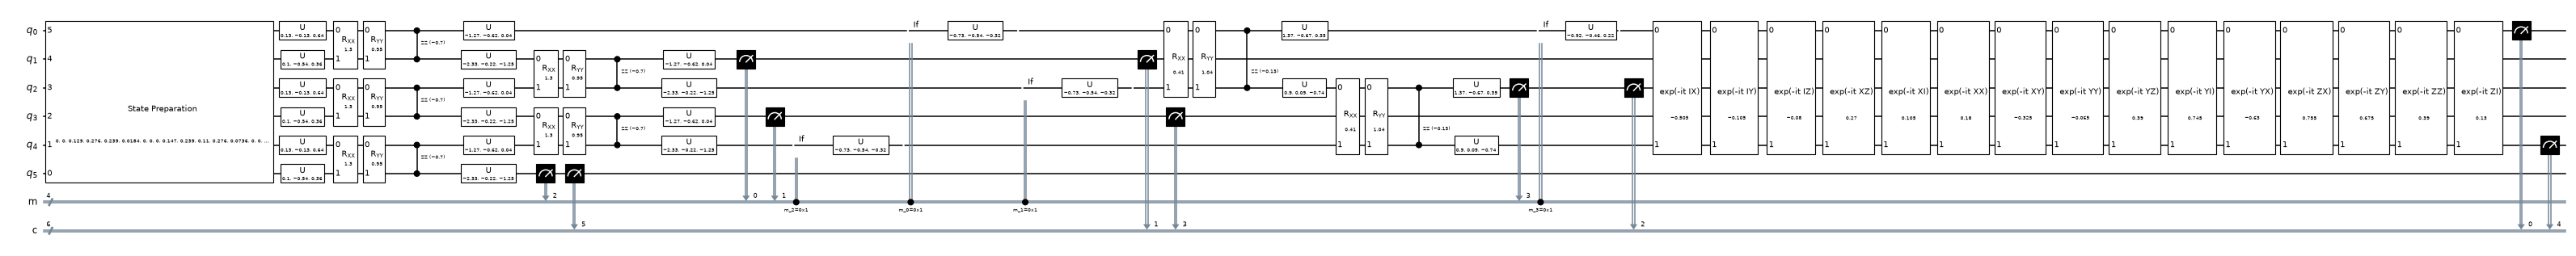

In [17]:
qc_dibujo = circuito_qiskit("QCNN", np.round(np.asarray(MODELOS["QCNN"]["init"](0)), 2), X35[0], dinamico=True)
qc_dibujo.draw("mpl", fold=-1, scale=0.55, style="bw")

### 7.2 Costo en hardware

Un circuito lógico de 51 operaciones no es lo que se ejecuta. El transpilador tiene que escribir la codificación en amplitudes con las compuertas nativas del dispositivo (CZ o ECR más rotaciones de un qubit) y agregar SWAP cuando los qubits no son vecinos en el chip. Transpilo la QCNN para una imagen con el nivel de optimización 3 sobre cuatro dispositivos simulados de IBM: Kyiv (Eagle, el de Anthony et al.) y Torino, Fez y Marrakesh (Heron).

In [18]:
from qiskit.transpiler import generate_preset_pass_manager

BACKENDS_FALSOS = {"Kyiv (Eagle r3)": FakeKyiv(), "Torino (Heron r1)": FakeTorino(),
                   "Fez (Heron r2)": FakeFez(), "Marrakesh (Heron r2)": FakeMarrakesh()}


def compuertas_2q(qc):
    return sum(1 for ins in qc.data if ins.operation.num_qubits == 2 and ins.operation.name not in ("barrier",))


th = np.asarray(MODELOS["QCNN"]["init"](0))
filas = []
for nombre_b, b in BACKENDS_FALSOS.items():
    pm = generate_preset_pass_manager(optimization_level=3, backend=b, seed_transpiler=0)
    fila = {"Dispositivo": nombre_b}
    for nombre in CUANTICOS:
        isa = pm.run(circuito_qiskit(nombre, MODELOS[nombre]["init"](0), X35[0]))
        fila[f"{nombre}: 2q / prof."] = f"{compuertas_2q(isa)} / {isa.depth()}"
    solo = QuantumCircuit(NQ); solo.append(StatePreparation(X35[0]), list(range(NQ))[::-1]); solo.measure_all()
    isa = pm.run(solo)
    fila["Solo codificación: 2q / prof."] = f"{compuertas_2q(isa)} / {isa.depth()}"
    filas.append(fila)
costo_hw = pd.DataFrame(filas).set_index("Dispositivo")
print("Compuertas de dos qubits / profundidad tras transpilar (nivel 3), para una imagen del par 3 y 5")
display(costo_hw)

Compuertas de dos qubits / profundidad tras transpilar (nivel 3), para una imagen del par 3 y 5


,QCNN: 2q / prof.,Control LOCC: 2q / prof.,Control LOCC-2: 2q / prof.,Control local: 2q / prof.,Solo codificación: 2q / prof.
Dispositivo,,,,,
Kyiv (Eagle r3),142 / 676,119 / 487,113 / 488,95 / 444,95 / 442
Torino (Heron r1),143 / 476,121 / 362,119 / 352,98 / 309,98 / 304
Fez (Heron r2),139 / 472,117 / 388,115 / 378,96 / 346,96 / 338
Marrakesh (Heron r2),139 / 466,117 / 382,115 / 372,96 / 346,96 / 338


### Lectura de la sección 7

1. La traducción a Qiskit es exacta. Para los cuatro modelos, la probabilidad de Qiskit coincide con la de PennyLane hasta $10^{-13}$, y la versión dinámica, con mediciones intermedias reales, coincide con la diferida dentro del error de muestreo de 200 000 *shots*. Los parámetros entrenados en PennyLane se pueden ejecutar tal cual en Qiskit y en hardware.
2. La codificación domina el costo. Escribir los 64 píxeles en las amplitudes cuesta unas 96 compuertas de dos qubits en los Heron y 95 en Kyiv, el 70% de las 139 a 143 de la QCNN completa. Los controles sin entrelazamiento no son mucho más baratos (113 a 121), porque cada *pooling* diferido es una rotación controlada que el hardware descompone en dos compuertas de dos qubits.
3. Los Heron producen circuitos bastante menos profundos que Kyiv (466 a 476 capas contra 676), por su conjunto de compuertas nativas y su conectividad. En la sección 11 uso un Heron.

## 8. Experimento 1: replicación en los dígitos 0 y 1

Repito el experimento principal de Anthony et al.: los dígitos 0 y 1, $N \in \{2, 5, 10, 20, 40, 80\}$, 10 repeticiones y 50 épocas, registrando todas las épocas.

In [19]:
TAMANOS_E1 = [2, 5, 10, 20, 40, 80]
REPS_E1 = 10
archivo_e1 = DIR_RES / "e1_replicacion_01.csv"

if archivo_e1.exists() and not RECALCULAR:
    e1 = pd.read_csv(archivo_e1)
else:
    X, y = cargar_par(0, 1)
    filas, t0 = [], time.perf_counter()
    for n in TAMANOS_E1:
        for rep in range(REPS_E1):
            Xtr, Xte, ytr, yte = particion(X, y, n, rep)
            log, _, _ = entrenar("QCNN", Xtr, ytr, Xte, yte, semilla=1000 * rep + n, epocas=50, registro=True)
            filas += [dict(r, n_train=n, rep=rep) for r in log]
            for nombre, acc in clasicos(Xtr, ytr, Xte, yte).items():
                filas.append(dict(step=50, test_acc=acc, n_train=n, rep=rep, modelo=nombre))
    e1 = pd.DataFrame(filas)
    e1["modelo"] = e1["modelo"].fillna("QCNN")
    e1.to_csv(archivo_e1, index=False)
    print(f"Experimento 1: {time.perf_counter() - t0:.0f} s")

In [20]:
cnn_anthony = pd.read_csv(DIR_ZEN / "Digits CNN" / "digits_classical_results_10reps.csv")
fin_anthony = log_anthony[log_anthony.step == 50]
fin_e1 = e1[e1.step == 50]

def resumen(df, col="test_acc"):
    return df.groupby("n_train")[col].apply(lambda v: "{:.3f} ± {:.3f}".format(*ic95(v)))

tabla_e1 = pd.DataFrame({
    "QCNN, esta implementación (exacta)": resumen(fin_e1[fin_e1.modelo == "QCNN"]),
    "QCNN, Anthony (FakeKyiv, 4000 shots)": resumen(fin_anthony),
    "CNN de 45 parámetros, Anthony": resumen(cnn_anthony[cnn_anthony.model == "CNN_tiny45"]),
    "CNN de 25 666 parámetros, Anthony": resumen(cnn_anthony[cnn_anthony.model == "CNN_25666"]),
    "Regresión logística, esta implementación": resumen(fin_e1[fin_e1.modelo == "Regresión logística"]),
})
tabla_e1.index.name = "N"
print("Exactitud de prueba en la última época: media ± IC 95% (10 repeticiones)")
display(tabla_e1)

Exactitud de prueba en la última época: media ± IC 95% (10 repeticiones)


,"QCNN, esta implementación (exacta)","QCNN, Anthony (FakeKyiv, 4000 shots)","CNN de 45 parámetros, Anthony","CNN de 25 666 parámetros, Anthony","Regresión logística, esta implementación"
N,,,,,
2,0.951 ± 0.026,0.751 ± 0.072,0.512 ± 0.028,0.944 ± 0.044,0.957 ± 0.024
5,0.974 ± 0.015,0.754 ± 0.127,0.506 ± 0.033,0.980 ± 0.016,0.987 ± 0.008
10,0.975 ± 0.014,0.940 ± 0.033,0.493 ± 0.023,0.989 ± 0.008,0.980 ± 0.015
20,0.993 ± 0.006,0.949 ± 0.026,0.530 ± 0.039,0.996 ± 0.005,0.998 ± 0.005
40,0.993 ± 0.009,0.952 ± 0.012,0.501 ± 0.034,0.993 ± 0.006,0.998 ± 0.003
80,0.993 ± 0.008,0.952 ± 0.030,0.508 ± 0.035,1.000 ± 0.000,1.000 ± 0.000


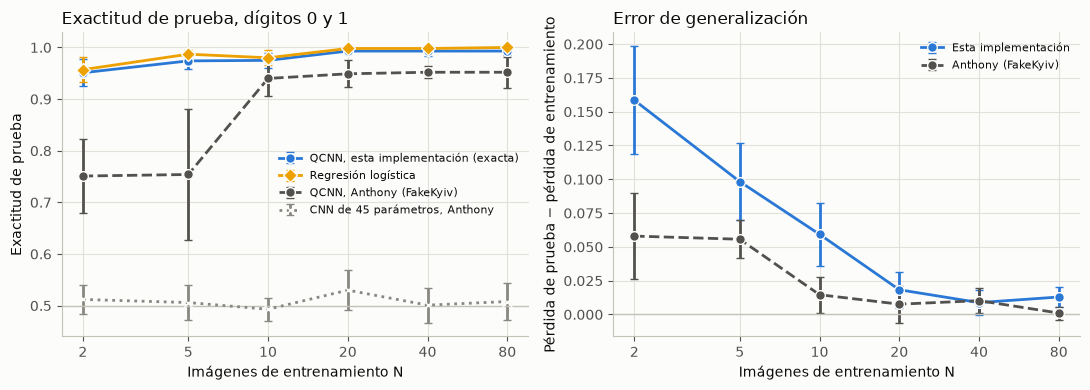

In [21]:
def curva(ax, df, nombre, color, marca, ls="-", col="test_acc", etiqueta=None):
    g = df.groupby("n_train")[col].apply(lambda v: ic95(v)).apply(pd.Series)
    ax.errorbar(g.index, g[0], yerr=g[1], color=color, marker=marca, ls=ls, capsize=3,
                label=etiqueta or nombre, markeredgecolor="#fcfcfb", markeredgewidth=1)
    return g

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
curva(ax, fin_e1[fin_e1.modelo == "QCNN"], "QCNN", COLOR["QCNN"], "o", etiqueta="QCNN, esta implementación (exacta)")
curva(ax, fin_e1[fin_e1.modelo == "Regresión logística"], "Regresión logística", COLOR["Regresión logística"], "D")
curva(ax, fin_anthony, "", GRIS_OSC, "o", ls="--", etiqueta="QCNN, Anthony (FakeKyiv)")
curva(ax, cnn_anthony[cnn_anthony.model == "CNN_tiny45"], "", GRIS, "x", ls=":", etiqueta="CNN de 45 parámetros, Anthony")
ax.axhline(0.5, color="#c3c2b7", lw=1)
ax.set_xscale("log"); ax.set_xticks(TAMANOS_E1, TAMANOS_E1); ax.minorticks_off()
ax.set_xlabel("Imágenes de entrenamiento N"); ax.set_ylabel("Exactitud de prueba")
ax.set_title("Exactitud de prueba, dígitos 0 y 1", loc="left"); ax.legend(fontsize=8, loc="center right")

ax = axes[1]
for df, nom, c, m, ls in [(fin_e1[fin_e1.modelo == "QCNN"], "Esta implementación", COLOR["QCNN"], "o", "-"),
                          (fin_anthony, "Anthony (FakeKyiv)", GRIS_OSC, "o", "--")]:
    d = df.assign(gen=df.test_cost - df.train_cost)
    curva(ax, d, nom, c, m, ls=ls, col="gen")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xscale("log"); ax.set_xticks(TAMANOS_E1, TAMANOS_E1); ax.minorticks_off()
ax.set_xlabel("Imágenes de entrenamiento N"); ax.set_ylabel("Pérdida de prueba − pérdida de entrenamiento")
ax.set_title("Error de generalización", loc="left"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

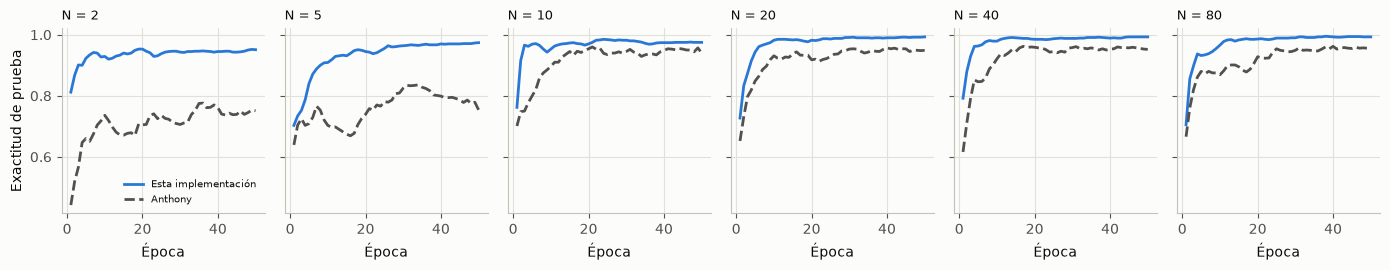

,Pérdida de entrenamiento (esta impl.),Pérdida de entrenamiento (Anthony)
n_train,,
2,0.228 ± 0.046,0.565 ± 0.035
5,0.269 ± 0.037,0.538 ± 0.027
10,0.309 ± 0.027,0.543 ± 0.023
20,0.321 ± 0.035,0.542 ± 0.016
40,0.305 ± 0.016,0.527 ± 0.017
80,0.305 ± 0.021,0.530 ± 0.014


In [22]:
# Curvas por época: exactitud de prueba media, esta implementación frente a los registros de Zenodo.
fig, axes = plt.subplots(1, 6, figsize=(14, 2.8), sharey=True)
q_e1 = e1[e1.modelo == "QCNN"]
for ax, n in zip(axes, TAMANOS_E1):
    for df, c, ls, nom in [(q_e1, COLOR["QCNN"], "-", "Esta implementación"), (log_anthony, GRIS_OSC, "--", "Anthony")]:
        g = df[df.n_train == n].groupby("step").test_acc.mean()
        ax.plot(g.index, g.values, color=c, ls=ls, label=nom)
    ax.set_title(f"N = {n}", loc="left", fontsize=9); ax.set_xlabel("Época")
axes[0].set_ylabel("Exactitud de prueba"); axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

perdida_final = pd.DataFrame({
    "Pérdida de entrenamiento (esta impl.)": resumen(q_e1[q_e1.step == 50], "train_cost"),
    "Pérdida de entrenamiento (Anthony)": resumen(fin_anthony, "train_cost"),
})
display(perdida_final)

### Lectura del experimento 1

1. La forma de las curvas coincide. En las dos implementaciones, la exactitud de prueba sube rápido con $N$ y se estabiliza desde 10 a 20 imágenes, y el error de generalización baja al crecer $N$.
2. El nivel no coincide. Con 2 imágenes obtengo 95.1% y ellos 75.1%; desde 20 imágenes, 99.3% y 95%. La pérdida de entrenamiento final también difiere: entre 0.23 y 0.32 aquí, entre 0.53 y 0.57 en su registro.
   - Mi hipótesis es que la diferencia viene del backend. El ruido del dispositivo y los 4 000 *shots* acercan las probabilidades de salida a 0.5, y los gradientes por diferencias finitas ($\varepsilon = 0.05$) son menos precisos que los automáticos.
   - Eso explicaría también que mi error de generalización sea mayor con pocos datos (0.16 frente a 0.06 con $N = 2$), porque sin ruido la pérdida de entrenamiento baja más.
   - En el avance no lo había comprobado. La sección 8.2 lo pone a prueba.
3. El par 0 y 1 no distingue entre modelos. Con las mismas particiones, la regresión logística obtiene 95.7% con 2 imágenes y 98% o más desde 5, por encima o al nivel de la QCNN en cada $N$, igual que en la Figura 10 de Anthony et al. Su CNN de 45 parámetros queda en el azar, mientras que una regresión logística de 65 parámetros resuelve la tarea.

### 8.1 Contraste con el entrenamiento original del tutorial

La comparación con Anthony et al. mezcla dos cosas: el código y el backend. Para separarlas, ejecuto el entrenamiento del tutorial sin modificar (`run_iterations` de su `demo.py`) y mi implementación con su mismo protocolo:

- su función de datos `load_digits_data`, que no estratifica las clases;
- su pérdida $1 - \bar p_{\text{correcta}}$;
- 100 épocas, 100 repeticiones, $N \in \{2, 5, 10, 20, 40, 80\}$ y 100 imágenes de prueba.

Las dos usan simulación exacta, así que cualquier diferencia vendría del código. Las semillas no coinciden, porque el tutorial inicializa los pesos con el generador global de NumPy, así que comparo distribuciones con una prueba t de Welch y no repetición por repetición. Fijo `np.random.seed(0)` antes de su corrida para que se pueda repetir; eso no toca su código.

El tutorial afirma: *"With 80 samples, we have achieved a model with accuracy greater than 97% in 100 training epochs."*

In [23]:
archivo_tut = DIR_RES / "e1b_tutorial_original.csv"
archivo_tut_mia = DIR_RES / "e1b_tutorial_esta_impl.csv"
TAM_TUT, REPS_TUT, EP_TUT = TUT["train_sizes"], TUT["n_reps"], TUT["n_epochs"]

if archivo_tut.exists() and not RECALCULAR:
    tut = pd.read_csv(archivo_tut)
else:
    np.random.seed(0)
    t0 = time.perf_counter()
    tut = pd.concat([TUT["run_iterations"](n_train=n) for n in TAM_TUT], ignore_index=True)
    tut = tut.apply(lambda col: col.map(float))
    tut.to_csv(archivo_tut, index=False)
    print(f"Tutorial original: {time.perf_counter() - t0:.0f} s")

if archivo_tut_mia.exists() and not RECALCULAR:
    tut_mia = pd.read_csv(archivo_tut_mia)
else:
    rng_datos = np.random.default_rng(1)
    filas, t0 = [], time.perf_counter()
    for n in TAM_TUT:
        for rep in range(REPS_TUT):
            xtr, ytr, xte, yte = TUT["load_digits_data"](n, TUT["n_test"], rng_datos)
            log, _, _ = entrenar("QCNN", np.asarray(xtr), np.asarray(ytr, float), np.asarray(xte),
                                 np.asarray(yte, float), semilla=10_000 + 1000 * rep + n,
                                 epocas=EP_TUT, perdida="1-p")
            filas.append(dict(log[-1], n_train=n, rep=rep))
    tut_mia = pd.DataFrame(filas)
    tut_mia.to_csv(archivo_tut_mia, index=False)
    print(f"Esta implementación con el protocolo del tutorial: {time.perf_counter() - t0:.0f} s")

fin_tut = tut[tut.step == EP_TUT]
filas = []
for n in TAM_TUT:
    a = fin_tut[fin_tut.n_train == n].test_acc.to_numpy()
    b = tut_mia[tut_mia.n_train == n].test_acc.to_numpy()
    ga = (fin_tut[fin_tut.n_train == n].test_cost - fin_tut[fin_tut.n_train == n].train_cost).to_numpy()
    gb = (tut_mia[tut_mia.n_train == n].test_cost - tut_mia[tut_mia.n_train == n].train_cost).to_numpy()
    filas.append({"N": n,
                  "Exactitud, tutorial original": "{:.3f} ± {:.3f}".format(*ic95(a)),
                  "Exactitud, esta implementación": "{:.3f} ± {:.3f}".format(*ic95(b)),
                  "Diferencia (pts)": f"{100 * (b.mean() - a.mean()):+.1f}",
                  "p (Welch)": round(stats.ttest_ind(a, b, equal_var=False).pvalue, 3),
                  "gen, tutorial": f"{ga.mean():.4f}",
                  "gen, esta impl.": f"{gb.mean():.4f}"})
comparacion_tut = pd.DataFrame(filas).set_index("N")
print(f"Exactitud de prueba en la época {EP_TUT}: media ± IC 95% ({REPS_TUT} repeticiones por tamaño)")
display(comparacion_tut)
a80 = fin_tut[fin_tut.n_train == 80].test_acc
print(f"Con N = 80: tutorial original {a80.mean():.3f}; esta implementación "
      f"{tut_mia[tut_mia.n_train == 80].test_acc.mean():.3f} (el tutorial afirma más de 0.97)")

Exactitud de prueba en la época 100: media ± IC 95% (100 repeticiones por tamaño)


,"Exactitud, tutorial original","Exactitud, esta implementación",Diferencia (pts),p (Welch),"gen, tutorial","gen, esta impl."
N,,,,,,
2,0.669 ± 0.043,0.680 ± 0.043,+1.1,0.712,0.3100,0.3042
5,0.786 ± 0.043,0.811 ± 0.039,+2.5,0.392,0.1434,0.1320
10,0.889 ± 0.031,0.888 ± 0.030,-0.1,0.982,0.0781,0.0764
20,0.937 ± 0.022,0.942 ± 0.019,+0.5,0.749,0.0401,0.0376
40,0.975 ± 0.007,0.971 ± 0.008,-0.4,0.449,0.0170,0.0185
80,0.975 ± 0.004,0.976 ± 0.007,+0.1,0.846,0.0121,0.0107


Con N = 80: tutorial original 0.975; esta implementación 0.976 (el tutorial afirma más de 0.97)


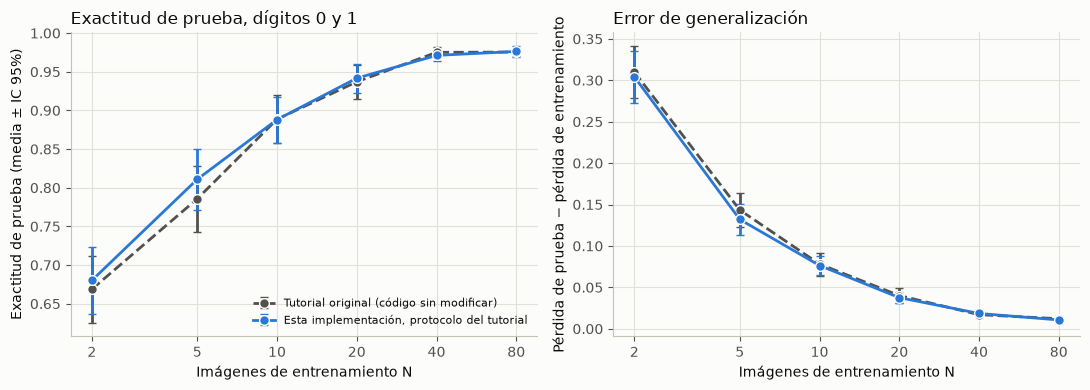

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
datos = [(fin_tut, "Tutorial original (código sin modificar)", GRIS_OSC, "o", "--"),
         (tut_mia, "Esta implementación, protocolo del tutorial", COLOR["QCNN"], "o", "-")]
for df, nom, c, m, ls in datos:
    curva(axes[0], df, nom, c, m, ls=ls)
    curva(axes[1], df.assign(gen=df.test_cost - df.train_cost), nom, c, m, ls=ls, col="gen")
for ax, titulo, ylab in [(axes[0], "Exactitud de prueba, dígitos 0 y 1", "Exactitud de prueba (media ± IC 95%)"),
                         (axes[1], "Error de generalización", "Pérdida de prueba − pérdida de entrenamiento")]:
    ax.set_xscale("log"); ax.set_xticks(TAM_TUT, TAM_TUT); ax.minorticks_off()
    ax.set_xlabel("Imágenes de entrenamiento N"); ax.set_ylabel(ylab); ax.set_title(titulo, loc="left")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [25]:
# ¿Cuántas particiones del tutorial tienen un solo dígito en el entrenamiento? Se repiten los mismos sorteos
# (misma semilla y orden) que usó la corrida de esta implementación.
rng_datos = np.random.default_rng(1)
una_clase = []
for n in TAM_TUT:
    for rep in range(REPS_TUT):
        _, ytr, _, _ = TUT["load_digits_data"](n, TUT["n_test"], rng_datos)
        una_clase.append(len(np.unique(np.asarray(ytr))) == 1)
t = tut_mia.assign(una_clase=una_clase)
t = t[t.n_train <= 5].groupby(["n_train", "una_clase"]).test_acc.agg(["count", "mean"]).round(3)
t.columns = ["Repeticiones", "Exactitud de prueba media"]
t.index.names = ["N", "Entrenamiento con un solo dígito"]
display(t)

Repeticiones  Exactitud de prueba media
N Entrenamiento con un solo dígito                                         
2 False                                       44                      0.917
  True                                        56                      0.494
5 False                                       95                      0.826
  True                                         5                      0.524

### Lectura del contraste con el tutorial

1. El circuito es el mismo. Con 5 juegos de parámetros al azar, la diferencia máxima entre mi probabilidad y la del tutorial, sobre las 360 imágenes, es de $10^{-15}$, el error de redondeo de la doble precisión. Cambiar los 6 pesos que la segunda capa del tutorial no usa deja la salida exactamente igual, así que su modelo tiene 45 parámetros efectivos de 51 nominales.
2. El entrenamiento da lo mismo. Con el protocolo del tutorial, las dos implementaciones difieren entre −0.4 y +2.5 puntos según $N$, y ningún valor $p$ baja de 0.39 (100 repeticiones por tamaño). El error de generalización coincide en todos los tamaños.
3. Con 80 imágenes, su código obtiene 97.5% y el mío 97.6%, por encima del 97% que afirma el tutorial.
4. Con pocos datos, el protocolo pesa más que el código. Con el protocolo del tutorial, la QCNN obtiene 67% a 68% con $N = 2$; con el de Anthony et al. (sección 8), 95%. La razón principal es que el tutorial no estratifica las clases:
   - en 56 de las 100 repeticiones con $N = 2$, las dos imágenes de entrenamiento son del mismo dígito, y en esas el modelo queda en 49%;
   - cuando hay una de cada clase, obtiene 91.7%.

   Para $N$ entre 5 y 20 queda una diferencia (82% a 94% frente a 97% a 99%) que puede venir de la pérdida, de las particiones desbalanceadas o de las épocas; no la he separado. Por eso cada comparación de este notebook usa las mismas particiones y el mismo protocolo para todos los modelos.

La sección 8.2 simula el backend ruidoso de Anthony et al.

### 8.2 Replicación en las condiciones de Anthony et al.

El avance dejó una hipótesis sin probar: mi QCNN exacta llega más alto que la de Anthony et al. (95% contra 75% con $N = 2$) porque ellos entrenaron con el simulador ruidoso FakeKyiv, 4 000 *shots* y gradientes por diferencias finitas ($\varepsilon = 0.05$).

Simular su entrenamiento directamente no es viable: con diferencias finitas cada época evalúa $2 \times 45 + 1 = 91$ veces el circuito por imagen, y la simulación ruidosa dinámica tarda más de un segundo por circuito con 4 000 *shots*. A ellos cada repetición les tomó entre 14 y 72 horas. Separo el problema en dos partes:

1. **Calibro el ruido de FakeKyiv.** Ejecuto el circuito dinámico transpilado para FakeKyiv en Aer con su modelo de ruido y comparo la probabilidad ruidosa con la exacta. Si la relación es aproximadamente lineal, $p_{\text{ruido}} \approx a + b\,p$, el ruido se resume en dos números.
2. **Entreno con ese modelo de ruido en JAX.** La probabilidad del modelo pasa a ser $a + b\,p(\theta, x)$; con *shots*, cada evaluación se reemplaza por una frecuencia binomial de 4 000 muestras, y el gradiente se estima con diferencias finitas centradas de paso 0.05, con muestras nuevas en cada evaluación.

Así separo tres efectos: el ruido de las compuertas (contracción hacia 0.5), el ruido de muestreo de los *shots* y el error de las diferencias finitas. Las cuatro variantes usan las particiones e inicializaciones del experimento 1 (dígitos 0 y 1, 10 repeticiones, 50 épocas) y se evalúan en prueba en las mismas condiciones en que se entrenaron.

Al final verifico el atajo: ejecuto modelos entrenados directamente en el simulador ruidoso de FakeKyiv y comparo con lo que predice el modelo lineal.

p_kyiv ≈ 0.316 + 0.379 · p_exacta   (R² = 0.977, residuo típico 0.013, error de muestreo esperado ≈ 0.005)
Una salida exacta de 0 o 1 queda en 0.316 o 0.696: el ruido conserva 38% de la distancia a 0.5


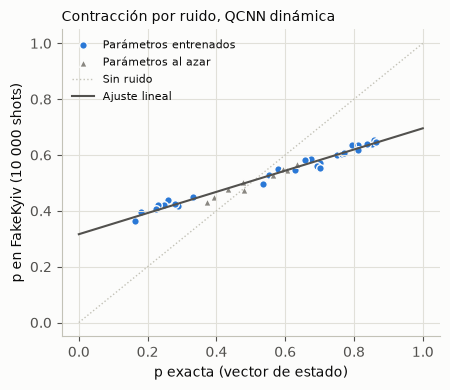

In [26]:
from qiskit_aer import AerSimulator

KYIV = FakeKyiv()
SIM_KYIV = AerSimulator.from_backend(KYIV, seed_simulator=11)
PM_KYIV = generate_preset_pass_manager(optimization_level=2, backend=KYIV, seed_transpiler=0)
SHOTS_ANTHONY = 4000
archivo_cal = DIR_RES / "f1c_calibracion_kyiv.csv"

X01, y01 = cargar_par(0, 1)
# Parámetros para calibrar: 10 QCNN entrenadas (N = 80, protocolo de Anthony) y 10 al azar, para cubrir todo el rango de p.
Xtr80, Xte80, ytr80, yte80 = particiones_lote((0, 1), 80, 10)
th_80, _ = entrenar_lote("QCNN", Xtr80, ytr80, [1000 * rep + 80 for rep in range(10)], epocas=50)
th_80 = np.asarray(th_80)

if archivo_cal.exists() and not RECALCULAR:
    cal = pd.read_csv(archivo_cal)
else:
    rng = np.random.default_rng(5)
    casos = [(th_80[r], Xte80[r][i], "entrenados") for r in range(10) for i in rng.choice(100, 3, replace=False)]
    casos += [(np.asarray(MODELOS["QCNN"]["init"](900 + s)), X01[i], "al azar")
              for s in range(10) for i in rng.choice(len(X01), 1)]
    t0 = time.perf_counter()
    isa = PM_KYIV.run([circuito_qiskit("QCNN", th, x, dinamico=True) for th, x, _ in casos])
    res = SIM_KYIV.run(isa, shots=10_000).result()
    cal = pd.DataFrame([dict(origen=o,
                             p_exacta=salida_desde_distribucion("QCNN", th, distribucion_exacta(circuito_qiskit("QCNN", th, x))),
                             p_kyiv=salida_desde_distribucion("QCNN", th, distribucion_conteos(res.get_counts(i))))
                        for i, (th, x, o) in enumerate(casos)])
    cal.to_csv(archivo_cal, index=False)
    print(f"Calibración: {len(casos)} circuitos dinámicos × 10 000 shots en {time.perf_counter() - t0:.0f} s")

b_kyiv, a_kyiv = np.polyfit(cal.p_exacta, cal.p_kyiv, 1)
r2 = np.corrcoef(cal.p_exacta, cal.p_kyiv)[0, 1] ** 2
resid = cal.p_kyiv - (a_kyiv + b_kyiv * cal.p_exacta)
print(f"p_kyiv ≈ {a_kyiv:.3f} + {b_kyiv:.3f} · p_exacta   (R² = {r2:.3f}, residuo típico {resid.std():.3f}, "
      f"error de muestreo esperado ≈ {np.sqrt(0.25 / 10_000):.3f})")
print(f"Una salida exacta de 0 o 1 queda en {a_kyiv:.3f} o {a_kyiv + b_kyiv:.3f}: el ruido conserva "
      f"{100 * b_kyiv:.0f}% de la distancia a 0.5")

fig, ax = plt.subplots(figsize=(4.6, 4))
for o, m in [("entrenados", "o"), ("al azar", "^")]:
    c = cal[cal.origen == o]
    ax.scatter(c.p_exacta, c.p_kyiv, marker=m, color=COLOR["QCNN"] if o == "entrenados" else GRIS, s=30,
               edgecolor="#fcfcfb", label=f"Parámetros {o}")
xs = np.linspace(0, 1, 2)
ax.plot(xs, xs, color="#c3c2b7", lw=1, ls=":", label="Sin ruido")
ax.plot(xs, a_kyiv + b_kyiv * xs, color=GRIS_OSC, lw=1.5, label="Ajuste lineal")
ax.set_xlabel("p exacta (vector de estado)"); ax.set_ylabel("p en FakeKyiv (10 000 shots)")
ax.set_title("Contracción por ruido, QCNN dinámica", loc="left", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [27]:
def entrenador_condiciones(a, b, shots, dif_finitas, epocas=50, lr=0.1, eps=0.05):
    # QCNN con salida a + b·p (ruido), frecuencias de `shots` muestras (0 = exacta) y gradiente por
    # diferencias finitas centradas (o automático). Vectorizado sobre repeticiones como entrenar_lote.
    pv = MODELOS["QCNN"]["pv"]
    opt = optax.adam(optax.cosine_decay_schedule(lr, epocas, alpha=0.95))

    def salida(th, X, k):
        q = a + b * pv(th, X)
        return jax.random.binomial(k, shots, q) / shots if shots else q

    def perdida(th, X, y, k):
        q = jnp.clip(salida(th, X, k), 1e-4, 1 - 1e-4)
        return -jnp.mean(y * jnp.log(q) + (1 - y) * jnp.log(1 - q))

    def gradiente(th, X, y, k):
        if not dif_finitas:
            return jax.grad(perdida)(th, X, y, k)
        E = eps * jnp.eye(th.shape[0])
        kp, km = jax.random.split(k)
        lp = jax.vmap(lambda e, kk: perdida(th + e, X, y, kk))(E, jax.random.split(kp, th.shape[0]))
        lm = jax.vmap(lambda e, kk: perdida(th - e, X, y, kk))(E, jax.random.split(km, th.shape[0]))
        return (lp - lm) / (2 * eps)

    def una(th0, X, y, Xt, yt, k):
        def paso(c, kk):
            th, st = c
            k1, k2 = jax.random.split(kk)
            l, g = perdida(th, X, y, k1), gradiente(th, X, y, k2)
            u, st = opt.update(g, st)
            return (optax.apply_updates(th, u), st), l
        kentr, kfin = jax.random.split(k)
        (th, _), ls = jax.lax.scan(paso, (th0, opt.init(th0)), jax.random.split(kentr, epocas))
        k1, k2, k3 = jax.random.split(kfin, 3)
        return dict(train_cost=perdida(th, X, y, k1), test_cost=perdida(th, Xt, yt, k2),
                    train_acc=jnp.mean((salida(th, X, k1) > 0.5) == y), test_acc=jnp.mean((salida(th, Xt, k3) > 0.5) == yt))

    return jax.jit(jax.vmap(una))


VARIANTES = {   # nombre: (a, b, shots, diferencias finitas)
    "Exacta, gradiente automático": (0.0, 1.0, 0, False),
    "Ruido FakeKyiv, gradiente automático": (a_kyiv, b_kyiv, 0, False),
    "4000 shots, diferencias finitas": (0.0, 1.0, SHOTS_ANTHONY, True),
    "Ruido FakeKyiv + 4000 shots + diferencias finitas": (a_kyiv, b_kyiv, SHOTS_ANTHONY, True),
}
archivo_f1c = DIR_RES / "f1c_condiciones_anthony.csv"
if archivo_f1c.exists() and not RECALCULAR:
    f1c = pd.read_csv(archivo_f1c)
else:
    filas, t0 = [], time.perf_counter()
    for nombre_v, (a, b, shots, df) in VARIANTES.items():
        fn = entrenador_condiciones(a, b, shots, df)
        for n in TAMANOS_E1:
            Xtr, Xte, ytr, yte = particiones_lote((0, 1), n, REPS_E1)
            th0 = jnp.stack([MODELOS["QCNN"]["init"](1000 * rep + n) for rep in range(REPS_E1)])
            claves = jax.random.split(jax.random.PRNGKey(n), REPS_E1)
            r = {k: np.asarray(v) for k, v in fn(th0, *map(jnp.asarray, (Xtr, ytr, Xte, yte)), claves).items()}
            filas += [dict(variante=nombre_v, n_train=n, rep=rep, **{k: float(v[rep]) for k, v in r.items()})
                      for rep in range(REPS_E1)]
        print(f"{nombre_v}: {time.perf_counter() - t0:.0f} s")
    f1c = pd.DataFrame(filas)
    f1c.to_csv(archivo_f1c, index=False)

tabla = pd.DataFrame({v: resumen(f1c[f1c.variante == v]) for v in VARIANTES})
tabla["Anthony et al. (Zenodo)"] = resumen(fin_anthony)
tabla.index.name = "N"
print("Exactitud de prueba en la época 50, dígitos 0 y 1: media ± IC 95% (10 repeticiones)")
display(tabla)
perd = pd.DataFrame({v: resumen(f1c[f1c.variante == v], "train_cost") for v in VARIANTES})
perd["Anthony et al. (Zenodo)"] = resumen(fin_anthony, "train_cost")
perd.index.name = "N"
print("Pérdida de entrenamiento en la época 50")
display(perd)

Exactitud de prueba en la época 50, dígitos 0 y 1: media ± IC 95% (10 repeticiones)


,"Exacta, gradiente automático","Ruido FakeKyiv, gradiente automático","4000 shots, diferencias finitas",Ruido FakeKyiv + 4000 shots + diferencias finitas,Anthony et al. (Zenodo)
N,,,,,
2,0.951 ± 0.026,0.962 ± 0.019,0.933 ± 0.036,0.815 ± 0.092,0.751 ± 0.072
5,0.974 ± 0.015,0.972 ± 0.015,0.937 ± 0.031,0.675 ± 0.148,0.754 ± 0.127
10,0.975 ± 0.014,0.974 ± 0.014,0.965 ± 0.025,0.930 ± 0.021,0.940 ± 0.033
20,0.993 ± 0.006,0.991 ± 0.009,0.994 ± 0.006,0.965 ± 0.037,0.949 ± 0.026
40,0.993 ± 0.009,0.994 ± 0.007,0.990 ± 0.009,0.980 ± 0.019,0.952 ± 0.012
80,0.993 ± 0.008,0.990 ± 0.010,0.994 ± 0.009,0.979 ± 0.015,0.952 ± 0.030


Pérdida de entrenamiento en la época 50


,"Exacta, gradiente automático","Ruido FakeKyiv, gradiente automático","4000 shots, diferencias finitas",Ruido FakeKyiv + 4000 shots + diferencias finitas,Anthony et al. (Zenodo)
N,,,,,
2,0.228 ± 0.046,0.486 ± 0.021,0.324 ± 0.055,0.600 ± 0.026,0.565 ± 0.035
5,0.269 ± 0.037,0.505 ± 0.016,0.338 ± 0.037,0.595 ± 0.016,0.538 ± 0.027
10,0.309 ± 0.027,0.528 ± 0.014,0.375 ± 0.036,0.603 ± 0.015,0.543 ± 0.023
20,0.321 ± 0.035,0.527 ± 0.013,0.351 ± 0.039,0.582 ± 0.017,0.542 ± 0.016
40,0.305 ± 0.016,0.527 ± 0.009,0.326 ± 0.023,0.565 ± 0.012,0.527 ± 0.017
80,0.305 ± 0.021,0.527 ± 0.012,0.319 ± 0.026,0.554 ± 0.014,0.530 ± 0.014


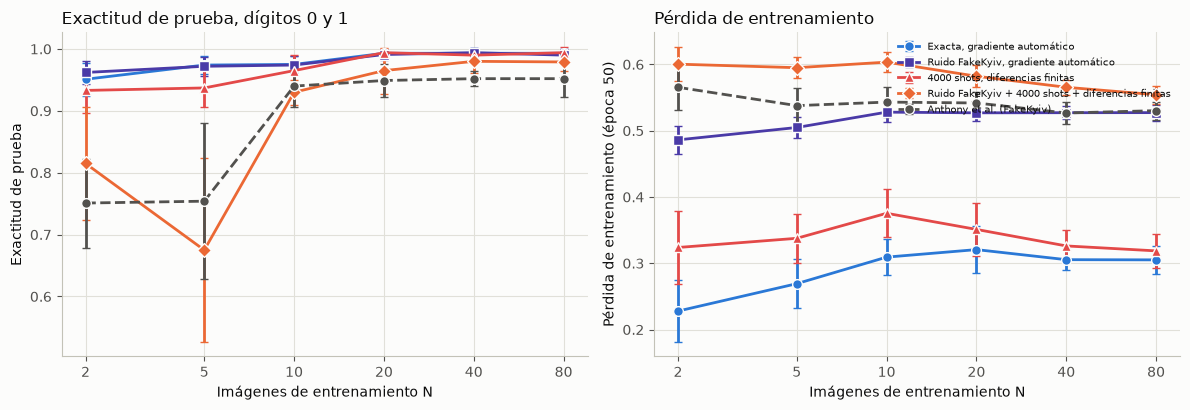

In [28]:
ESTILO_V = {"Exacta, gradiente automático": (COLOR["QCNN"], "o", "-"),
            "Ruido FakeKyiv, gradiente automático": ("#4a3aa7", "s", "-"),
            "4000 shots, diferencias finitas": ("#e34948", "^", "-"),
            "Ruido FakeKyiv + 4000 shots + diferencias finitas": ("#eb6834", "D", "-")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for v, (c, m, ls) in ESTILO_V.items():
    curva(axes[0], f1c[f1c.variante == v], v, c, m, ls=ls)
    curva(axes[1], f1c[f1c.variante == v], v, c, m, ls=ls, col="train_cost")
for ax, col in [(axes[0], "test_acc"), (axes[1], "train_cost")]:
    curva(ax, fin_anthony, "", GRIS_OSC, "o", ls="--", col=col, etiqueta="Anthony et al. (FakeKyiv)")
    ax.set_xscale("log"); ax.set_xticks(TAMANOS_E1, TAMANOS_E1); ax.minorticks_off()
    ax.set_xlabel("Imágenes de entrenamiento N")
axes[0].set_ylabel("Exactitud de prueba"); axes[0].set_title("Exactitud de prueba, dígitos 0 y 1", loc="left")
axes[1].set_ylabel("Pérdida de entrenamiento (época 50)"); axes[1].set_title("Pérdida de entrenamiento", loc="left")
axes[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout(); plt.show()

**Comprobación directa en FakeKyiv.** El modelo lineal es un atajo. Para verificarlo, tomo las QCNN entrenadas con $N = 80$ en simulación exacta (repeticiones 0 a 2) y ejecuto sus 100 imágenes de prueba en el simulador ruidoso de FakeKyiv, con el circuito dinámico y 4 000 *shots*. Si el atajo es bueno, la exactitud medida debe coincidir con la que predice $a + b\,p$.

In [29]:
archivo_kyiv = DIR_RES / "f1c_inferencia_kyiv.csv"
if archivo_kyiv.exists() and not RECALCULAR:
    inf_kyiv = pd.read_csv(archivo_kyiv)
else:
    filas, t0 = [], time.perf_counter()
    for rep in range(3):
        qcs = [circuito_qiskit("QCNN", th_80[rep], x, dinamico=True) for x in Xte80[rep]]
        res = SIM_KYIV.run(PM_KYIV.run(qcs), shots=SHOTS_ANTHONY).result()
        for i, x in enumerate(Xte80[rep]):
            filas.append(dict(rep=rep, y=yte80[rep][i],
                              p_exacta=salida_desde_distribucion("QCNN", th_80[rep], distribucion_exacta(circuito_qiskit("QCNN", th_80[rep], x))),
                              p_kyiv=salida_desde_distribucion("QCNN", th_80[rep], distribucion_conteos(res.get_counts(i)))))
    inf_kyiv = pd.DataFrame(filas)
    inf_kyiv.to_csv(archivo_kyiv, index=False)
    print(f"Inferencia en FakeKyiv: {time.perf_counter() - t0:.0f} s")

inf_kyiv["p_lineal"] = a_kyiv + b_kyiv * inf_kyiv.p_exacta
comp = inf_kyiv.groupby("rep").apply(lambda d: pd.Series({
    "Exacta": np.mean((d.p_exacta > 0.5) == d.y),
    "Predicha por a + b·p": np.mean((d.p_lineal > 0.5) == d.y),
    "Medida en FakeKyiv": np.mean((d.p_kyiv > 0.5) == d.y),
    "Rango de p en FakeKyiv": f"{d.p_kyiv.min():.2f} – {d.p_kyiv.max():.2f}"}))
comp.index.name = "Repetición (N = 80)"
display(comp)

,Exacta,Predicha por a + b·p,Medida en FakeKyiv,Rango de p en FakeKyiv
Repetición (N = 80),,,,
0,0.99,1.00,1.00,0.37 – 0.71
1,1.00,1.00,1.00,0.40 – 0.63
2,0.98,0.97,0.98,0.36 – 0.68


### Lectura de la sección 8.2

1. **El ruido de FakeKyiv es casi una contracción lineal hacia 0.5.** La salida ruidosa sigue $p_{\text{ruido}} \approx 0.316 + 0.379\,p$ con $R^2 = 0.977$. Una QCNN que en simulación exacta está completamente segura ($p = 0$ o $1$) en FakeKyiv nunca sale de $[0.32, 0.70]$. El atajo funciona también para clasificar: con modelos entrenados de forma exacta, la exactitud que predice el modelo lineal coincide con la medida en FakeKyiv (98% a 100% en las tres repeticiones).
2. **Ninguno de los tres efectos explica por separado la caída de Anthony et al.** Solo el ruido deja la exactitud en el nivel exacto (96.2% con $N = 2$); solo los *shots* y las diferencias finitas, también (93.3%). El ruido solo sí explica casi toda la pérdida de entrenamiento alta (0.49 a 0.53, frente a 0.53 a 0.57 de Anthony et al.), porque la contracción impide que las probabilidades se acerquen a 0 o 1.
3. **La combinación sí la reproduce.** Con ruido, 4 000 *shots* y diferencias finitas, la QCNN obtiene 81.5% con $N = 2$ y 67.5% con $N = 5$ (Anthony et al.: 75.1% y 75.4%), sube a 93% con $N = 10$ (94%) y queda entre 96.5% y 98% desde 20 imágenes (95%). La pérdida de entrenamiento queda entre 0.55 y 0.60, la de su registro entre 0.53 y 0.57. Con $N = 5$, cuatro de las diez repeticiones quedan en 50% o menos: el entrenamiento no despega. Esa bimodalidad explica también su intervalo de ±12.7 puntos.
4. **El mecanismo.** El ruido multiplica todos los gradientes por 0.38, porque la contracción es lineal. El error de las diferencias finitas, en cambio, viene de los *shots* y no se achica: con 4 000 muestras, cada probabilidad tiene un error de hasta 0.008, que dividido por $2\varepsilon = 0.1$ da un error de 0.08 en cada componente del gradiente. Con pocas imágenes, la señal contraída queda por debajo de ese error y Adam avanza al azar.

Con esto la replicación queda cerrada. La diferencia de nivel entre mi QCNN y la de Anthony et al. viene del backend, y en particular de entrenar con ruido y diferencias finitas al mismo tiempo; no de la arquitectura ni del código. El atajo del modelo lineal no reproduce todo: en simulación los resultados con $N \ge 20$ quedan 1 a 3 puntos por encima de los suyos, quizá porque el ruido real no es exactamente lineal o porque su programa de diferencias finitas no es el centrado que supuse.

## 9. Experimento 2: ablación final

Es el experimento que la entrega 3 propuso y que el avance corrió en versión preliminar (2 pares, 10 repeticiones, 100 épocas). Esta versión cambia cuatro cosas:

| | Avance | Entrega final |
|---|---|---|
| Pares de dígitos | 0 y 1, 3 y 5 | 0 y 1, 3 y 5, 2 y 3, 3 y 8 |
| Repeticiones | 10 | 20 |
| Épocas | 100 | 200 |
| Controles | LOCC y local | LOCC, LOCC-2 y local |

Con 20 repeticiones, la desviación típica de la diferencia pareada que midió el avance (unos 2 puntos con $N \ge 20$) da intervalos de ±1 punto, lo justo para distinguir diferencias de 1 a 2 puntos. Uso $N \in \{2, 5, 10, 20, 40, 80, 200\}$ y 100 imágenes de prueba. Las repeticiones 0 a 9 usan las mismas particiones e inicializaciones que el avance.

Cada par se guarda en su propio archivo, junto con los parámetros entrenados, que la sección 11 usa en hardware.

In [30]:
TAMANOS_F = [2, 5, 10, 20, 40, 80, 200]
REPS_F = 20
EPOCAS_F = 200
CLASICOS = ["Regresión logística", "Lineal sobre un cuerpo"]
ORDEN = CUANTICOS + CLASICOS


def nombre_par(par):
    return f"{par[0]} y {par[1]}"


def correr_ablacion(par, modelos=CUANTICOS, tamanos=TAMANOS_F, reps=REPS_F, epocas=EPOCAS_F, etiqueta="f2"):
    archivo = DIR_RES / f"{etiqueta}_ablacion_{par[0]}{par[1]}.csv"
    archivo_th = DIR_RES / f"{etiqueta}_parametros_{par[0]}{par[1]}.npz"
    if archivo.exists() and not RECALCULAR:
        return pd.read_csv(archivo)
    filas, thetas, t0 = [], {}, time.perf_counter()
    for n in tamanos:
        Xtr, Xte, ytr, yte = particiones_lote(par, n, reps)
        semillas = [1000 * rep + n for rep in range(reps)]
        for nombre in modelos:
            th, ls = entrenar_lote(nombre, Xtr, ytr, semillas, epocas)
            acc_tr, l_tr = evaluar_lote(nombre, th, Xtr, ytr)
            acc_te, l_te = evaluar_lote(nombre, th, Xte, yte)
            ls = np.asarray(ls)
            thetas[f"{nombre}|{n}"] = np.asarray(th)
            for rep in range(reps):
                filas.append(dict(par=nombre_par(par), n_train=n, rep=rep, modelo=nombre,
                                  train_acc=acc_tr[rep], test_acc=acc_te[rep], train_cost=l_tr[rep], test_cost=l_te[rep],
                                  perdida_ep_mitad=ls[rep, epocas // 2 - 1],
                                  cambio_ultimo_10pct=(ls[rep, -1] - ls[rep, int(0.9 * epocas) - 1]) / ls[rep, int(0.9 * epocas) - 1]))
        if etiqueta == "f2":
            for rep in range(reps):
                for nombre, acc in clasicos(Xtr[rep], ytr[rep], Xte[rep], yte[rep]).items():
                    filas.append(dict(par=nombre_par(par), n_train=n, rep=rep, modelo=nombre, test_acc=acc))
    df = pd.DataFrame(filas)
    df.to_csv(archivo, index=False)
    np.savez_compressed(archivo_th, **thetas)
    print(f"Par {par}: {time.perf_counter() - t0:.0f} s")
    return df

In [31]:
f2 = pd.concat([correr_ablacion(par) for par in PARES], ignore_index=True)
print(f"{len(f2)} filas: {f2.modelo.nunique()} modelos, {f2.par.nunique()} pares, {f2.n_train.nunique()} tamaños, "
      f"{f2.rep.nunique()} repeticiones")

3360 filas: 6 modelos, 4 pares, 7 tamaños, 20 repeticiones


### 9.1 Exactitud según el número de imágenes

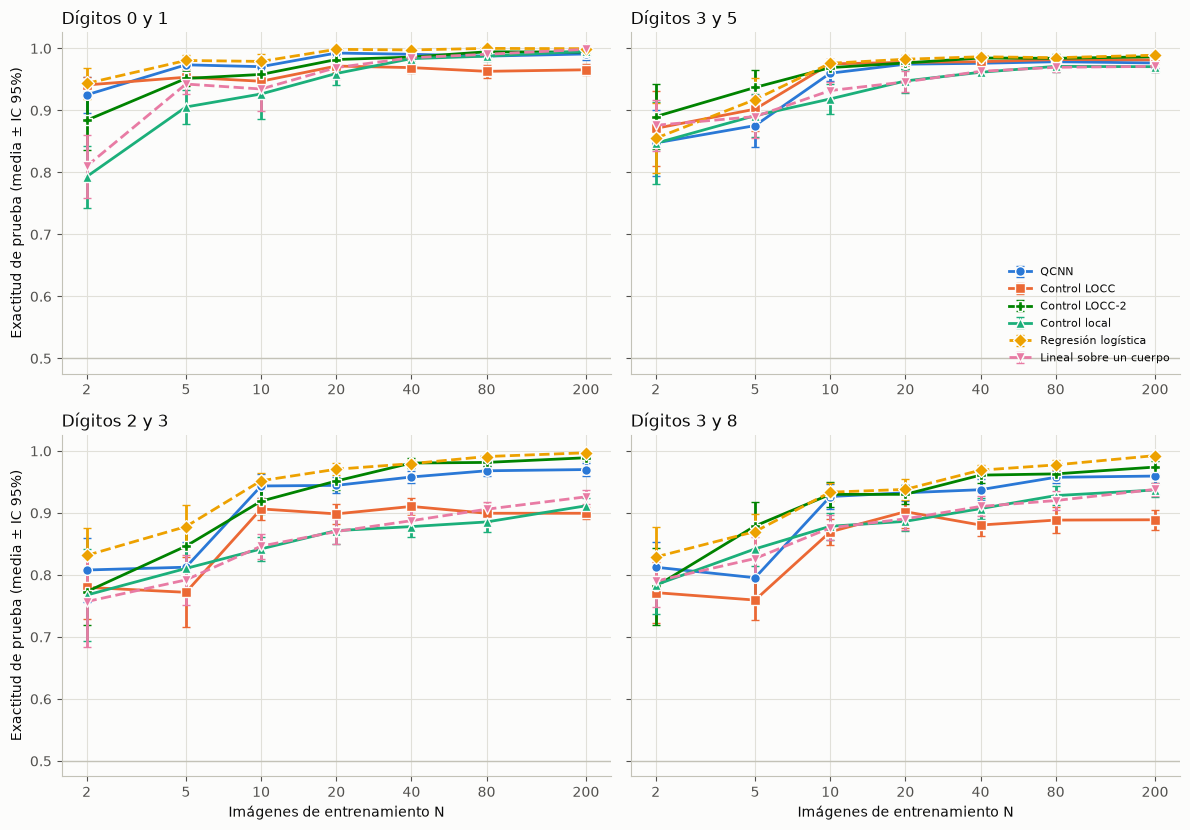

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.4), sharey=True)
for ax, par in zip(axes.flat, PARES):
    d = f2[f2.par == nombre_par(par)]
    for nombre in ORDEN:
        curva(ax, d[d.modelo == nombre], nombre, COLOR[nombre], MARCA[nombre],
              ls="-" if nombre in CUANTICOS else "--")
    ax.axhline(0.5, color="#c3c2b7", lw=1)
    ax.set_xscale("log"); ax.set_xticks(TAMANOS_F, TAMANOS_F); ax.minorticks_off()
    ax.set_title(f"Dígitos {nombre_par(par)}", loc="left")
for ax in axes[1]:
    ax.set_xlabel("Imágenes de entrenamiento N")
for ax in axes[:, 0]:
    ax.set_ylabel("Exactitud de prueba (media ± IC 95%)")
axes[0, 1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [33]:
for par in PARES:
    d = f2[f2.par == nombre_par(par)]
    t = pd.DataFrame({m: resumen(d[d.modelo == m]) for m in ORDEN})
    t.index.name = "N"
    print(f"Dígitos {nombre_par(par)}: exactitud de prueba, media ± IC 95% ({REPS_F} repeticiones)")
    display(t)

Dígitos 0 y 1: exactitud de prueba, media ± IC 95% (20 repeticiones)


,QCNN,Control LOCC,Control LOCC-2,Control local,Regresión logística,Lineal sobre un cuerpo
N,,,,,,
2,0.925 ± 0.030,0.941 ± 0.012,0.884 ± 0.048,0.793 ± 0.050,0.944 ± 0.025,0.810 ± 0.051
5,0.973 ± 0.012,0.953 ± 0.013,0.951 ± 0.012,0.905 ± 0.027,0.980 ± 0.008,0.943 ± 0.017
10,0.970 ± 0.015,0.947 ± 0.020,0.958 ± 0.018,0.926 ± 0.040,0.979 ± 0.012,0.935 ± 0.036
20,0.992 ± 0.006,0.971 ± 0.009,0.982 ± 0.009,0.959 ± 0.019,0.998 ± 0.002,0.969 ± 0.018
40,0.990 ± 0.006,0.969 ± 0.009,0.986 ± 0.006,0.983 ± 0.011,0.997 ± 0.003,0.985 ± 0.011
80,0.987 ± 0.006,0.963 ± 0.010,0.994 ± 0.003,0.987 ± 0.008,1.000 ± 0.000,0.990 ± 0.009
200,0.991 ± 0.009,0.965 ± 0.009,0.994 ± 0.004,0.995 ± 0.003,1.000 ± 0.001,0.998 ± 0.002


Dígitos 3 y 5: exactitud de prueba, media ± IC 95% (20 repeticiones)


,QCNN,Control LOCC,Control LOCC-2,Control local,Regresión logística,Lineal sobre un cuerpo
N,,,,,,
2,0.847 ± 0.054,0.871 ± 0.060,0.890 ± 0.053,0.847 ± 0.066,0.855 ± 0.056,0.876 ± 0.041
5,0.875 ± 0.034,0.902 ± 0.035,0.937 ± 0.028,0.891 ± 0.035,0.917 ± 0.034,0.890 ± 0.035
10,0.960 ± 0.012,0.975 ± 0.008,0.969 ± 0.010,0.918 ± 0.025,0.976 ± 0.006,0.932 ± 0.014
20,0.974 ± 0.008,0.977 ± 0.006,0.976 ± 0.010,0.947 ± 0.019,0.983 ± 0.006,0.946 ± 0.017
40,0.976 ± 0.006,0.978 ± 0.006,0.984 ± 0.006,0.961 ± 0.006,0.986 ± 0.005,0.963 ± 0.008
80,0.978 ± 0.008,0.982 ± 0.006,0.984 ± 0.007,0.971 ± 0.009,0.985 ± 0.004,0.970 ± 0.008
200,0.976 ± 0.007,0.981 ± 0.006,0.986 ± 0.005,0.970 ± 0.009,0.989 ± 0.005,0.971 ± 0.010


Dígitos 2 y 3: exactitud de prueba, media ± IC 95% (20 repeticiones)


,QCNN,Control LOCC,Control LOCC-2,Control local,Regresión logística,Lineal sobre un cuerpo
N,,,,,,
2,0.808 ± 0.051,0.780 ± 0.051,0.773 ± 0.054,0.767 ± 0.074,0.831 ± 0.045,0.757 ± 0.073
5,0.812 ± 0.040,0.772 ± 0.057,0.846 ± 0.035,0.810 ± 0.040,0.878 ± 0.035,0.792 ± 0.040
10,0.943 ± 0.020,0.906 ± 0.017,0.919 ± 0.020,0.842 ± 0.019,0.952 ± 0.012,0.847 ± 0.020
20,0.944 ± 0.013,0.898 ± 0.016,0.951 ± 0.015,0.871 ± 0.021,0.970 ± 0.010,0.870 ± 0.021
40,0.958 ± 0.010,0.910 ± 0.014,0.980 ± 0.008,0.878 ± 0.016,0.979 ± 0.006,0.887 ± 0.016
80,0.968 ± 0.008,0.899 ± 0.014,0.981 ± 0.006,0.885 ± 0.016,0.991 ± 0.005,0.906 ± 0.012
200,0.970 ± 0.010,0.899 ± 0.010,0.989 ± 0.004,0.911 ± 0.013,0.997 ± 0.003,0.926 ± 0.011


Dígitos 3 y 8: exactitud de prueba, media ± IC 95% (20 repeticiones)


,QCNN,Control LOCC,Control LOCC-2,Control local,Regresión logística,Lineal sobre un cuerpo
N,,,,,,
2,0.812 ± 0.040,0.771 ± 0.050,0.781 ± 0.062,0.784 ± 0.046,0.829 ± 0.048,0.790 ± 0.041
5,0.795 ± 0.035,0.759 ± 0.032,0.879 ± 0.038,0.842 ± 0.028,0.870 ± 0.028,0.827 ± 0.035
10,0.926 ± 0.020,0.869 ± 0.021,0.930 ± 0.021,0.878 ± 0.022,0.933 ± 0.014,0.876 ± 0.020
20,0.932 ± 0.013,0.902 ± 0.026,0.930 ± 0.015,0.886 ± 0.015,0.938 ± 0.017,0.890 ± 0.018
40,0.937 ± 0.017,0.880 ± 0.018,0.961 ± 0.012,0.907 ± 0.017,0.969 ± 0.008,0.911 ± 0.016
80,0.957 ± 0.010,0.888 ± 0.021,0.963 ± 0.010,0.928 ± 0.015,0.978 ± 0.008,0.920 ± 0.016
200,0.959 ± 0.013,0.889 ± 0.016,0.974 ± 0.009,0.937 ± 0.012,0.992 ± 0.003,0.938 ± 0.011


### 9.2 Diferencias pareadas

Todos los modelos ven las mismas imágenes en cada repetición, así que comparo la QCNN con cada control repetición por repetición. Reporto la diferencia media con su intervalo de 95% y el valor $p$ de una prueba t pareada. Son 84 comparaciones (4 pares × 7 tamaños × 3 controles), así que corrijo los valores $p$ por comparaciones múltiples con el método de Holm, que controla la probabilidad de declarar al menos un falso positivo.

Para decir que dos modelos "no se distinguen" no basta con un valor $p$ alto. Uso un criterio de equivalencia: si el intervalo de 95% de la diferencia queda entero dentro de ±2 puntos, la diferencia, de existir, es menor que la resolución práctica del experimento (100 imágenes de prueba).

In [34]:
def holm(p):
    p = np.asarray(p, float)
    orden = np.argsort(p)
    ajustado = np.empty_like(p)
    acumulado = 0.0
    for i, j in enumerate(orden):
        acumulado = max(acumulado, min(1.0, (len(p) - i) * p[j]))
        ajustado[j] = acumulado
    return ajustado


CONTROLES = ["Control LOCC", "Control LOCC-2", "Control local"]
MARGEN_EQ = 0.02
filas = []
for par in PARES:
    d = f2[f2.par == nombre_par(par)].pivot_table(index=["n_train", "rep"], columns="modelo", values="test_acc")
    for n in TAMANOS_F:
        dn = d.loc[n]
        for control in CONTROLES:
            dif = dn["QCNN"] - dn[control]
            m, h = ic95(dif)
            p = stats.ttest_rel(dn["QCNN"], dn[control]).pvalue if dif.std() > 0 else 1.0
            filas.append(dict(par=nombre_par(par), N=n, control=control, media=m, ic=h, p=p))
dif_f2 = pd.DataFrame(filas)
dif_f2["p_holm"] = holm(dif_f2.p)
significativa = dif_f2.p_holm < 0.05
equivalente = (dif_f2.media - dif_f2.ic > -MARGEN_EQ) & (dif_f2.media + dif_f2.ic < MARGEN_EQ)
dif_f2["veredicto"] = np.select([significativa & (dif_f2.media > 0), significativa & (dif_f2.media < 0), equivalente],
                                ["QCNN mejor", "control mejor", "equivalentes (±2 pts)"], default="no concluyente")
dif_f2["diferencia"] = dif_f2.apply(lambda r: f"{100 * r.media:+.1f} ± {100 * r.ic:.1f}", axis=1)

display(dif_f2.pivot_table(index=["par", "N"], columns="control", values="diferencia", aggfunc="first")
        .reindex(columns=CONTROLES).rename(columns=lambda c: f"QCNN − {c} (pts)"))
display(dif_f2.pivot_table(index=["par", "N"], columns="control", values="veredicto", aggfunc="first")
        .reindex(columns=CONTROLES))
print("Veredictos por control (28 comparaciones cada uno):")
display(dif_f2.groupby(["control", "veredicto"]).size().unstack(fill_value=0))

control   QCNN − Control LOCC (pts) QCNN − Control LOCC-2 (pts)  \
par   N                                                           
0 y 1 2                  -1.6 ± 2.7                  +4.1 ± 4.4   
      5                  +2.0 ± 1.1                  +2.2 ± 1.5   
      10                 +2.3 ± 1.8                  +1.2 ± 1.1   
      20                 +2.1 ± 0.8                  +1.1 ± 1.0   
      40                 +2.2 ± 0.8                  +0.5 ± 0.5   
      80                 +2.4 ± 1.0                  -0.7 ± 0.7   
      200                +2.6 ± 0.8                  -0.3 ± 0.6   
2 y 3 2                  +2.8 ± 3.8                  +3.5 ± 3.5   
      5                  +4.1 ± 4.1                  -3.4 ± 3.8   
      10                 +3.7 ± 2.2                  +2.4 ± 2.4   
      20                 +4.6 ± 1.3                  -0.7 ± 1.2   
      40                 +4.8 ± 1.3                  -2.2 ± 1.2   
      80                 +6.8 ± 1.3                  -1.3 ± 0.9   
      200                +7.0 ± 1.2                  -1.9 ± 1.1   
3 y 5 2                  -2.4 ± 3.8                  -4.3 ± 2.8   
      5                  -2.6 ± 3.9                  -6.1 ± 3.4   
      10                 -1.5 ± 1.0                  -0.9 ± 1.5   
      20                 -0.3 ± 0.7                  -0.2 ± 1.2   
      40                 -0.2 ± 0.7                  -0.8 ± 0.6   
      80                 -0.3 ± 0.7                  -0.5 ± 1.0   
      200                -0.5 ± 0.5                  -1.0 ± 0.7   
3 y 8 2                  +4.1 ± 3.9                  +3.1 ± 4.4   
      5                  +3.6 ± 2.6                  -8.3 ± 4.9   
      10                 +5.7 ± 2.6                  -0.4 ± 2.4   
      20                 +3.1 ± 2.3                  +0.3 ± 1.2   
      40                 +5.7 ± 1.7                  -2.3 ± 2.0   
      80                 +6.9 ± 1.9                  -0.5 ± 1.3   
      200                +7.0 ± 1.4                  -1.5 ± 1.2   

control   QCNN − Control local (pts)  
par   N                               
0 y 1 2                  +13.2 ± 4.2  
      5                   +6.8 ± 2.6  
      10                  +4.4 ± 3.9  
      20                  +3.3 ± 2.1  
      40                  +0.7 ± 1.4  
      80                  +0.0 ± 1.0  
      200                 -0.4 ± 0.9  
2 y 3 2                   +4.1 ± 5.3  
      5                   +0.2 ± 3.7  
      10                 +10.1 ± 2.4  
      20                  +7.3 ± 2.1  
      40                  +8.0 ± 1.5  
      80                  +8.2 ± 1.6  
      200                 +5.8 ± 1.6  
3 y 5 2                   +0.0 ± 3.3  
      5                   -1.6 ± 3.2  
      10                  +4.1 ± 3.0  
      20                  +2.7 ± 2.1  
      40                  +1.4 ± 0.8  
      80                  +0.7 ± 1.1  
      200                 +0.6 ± 0.9  
3 y 8 2                   +2.9 ± 5.7  
      5                   -4.7 ± 3.9  
      10                  +4.8 ± 3.5  
      20                  +4.6 ± 1.8  
      40                  +3.0 ± 2.4  
      80                  +3.0 ± 1.5  
      200                 +2.2 ± 1.7

control             Control LOCC         Control LOCC-2          Control local
par   N                                                                       
0 y 1 2           no concluyente         no concluyente             QCNN mejor
      5           no concluyente         no concluyente             QCNN mejor
      10          no concluyente         no concluyente         no concluyente
      20              QCNN mejor         no concluyente         no concluyente
      40              QCNN mejor  equivalentes (±2 pts)         no concluyente
      80              QCNN mejor  equivalentes (±2 pts)  equivalentes (±2 pts)
      200             QCNN mejor  equivalentes (±2 pts)  equivalentes (±2 pts)
2 y 3 2           no concluyente         no concluyente         no concluyente
      5           no concluyente         no concluyente         no concluyente
      10          no concluyente         no concluyente             QCNN mejor
      20              QCNN mejor  equivalentes (±2 pts)             QCNN mejor
      40              QCNN mejor          control mejor             QCNN mejor
      80              QCNN mejor         no concluyente             QCNN mejor
      200             QCNN mejor         no concluyente             QCNN mejor
3 y 5 2           no concluyente         no concluyente         no concluyente
      5           no concluyente         no concluyente         no concluyente
      10          no concluyente         no concluyente         no concluyente
      20   equivalentes (±2 pts)  equivalentes (±2 pts)         no concluyente
      40   equivalentes (±2 pts)  equivalentes (±2 pts)         no concluyente
      80   equivalentes (±2 pts)  equivalentes (±2 pts)  equivalentes (±2 pts)
      200  equivalentes (±2 pts)  equivalentes (±2 pts)  equivalentes (±2 pts)
3 y 8 2           no concluyente         no concluyente         no concluyente
      5           no concluyente         no concluyente         no concluyente
      10              QCNN mejor         no concluyente         no concluyente
      20          no concluyente  equivalentes (±2 pts)             QCNN mejor
      40              QCNN mejor         no concluyente         no concluyente
      80              QCNN mejor  equivalentes (±2 pts)             QCNN mejor
      200             QCNN mejor         no concluyente         no concluyente

Veredictos por control (28 comparaciones cada uno):


veredicto,QCNN mejor,control mejor,equivalentes (±2 pts),no concluyente
control,,,,
Control LOCC,12,0,4,12
Control LOCC-2,0,1,10,17
Control local,9,0,4,15


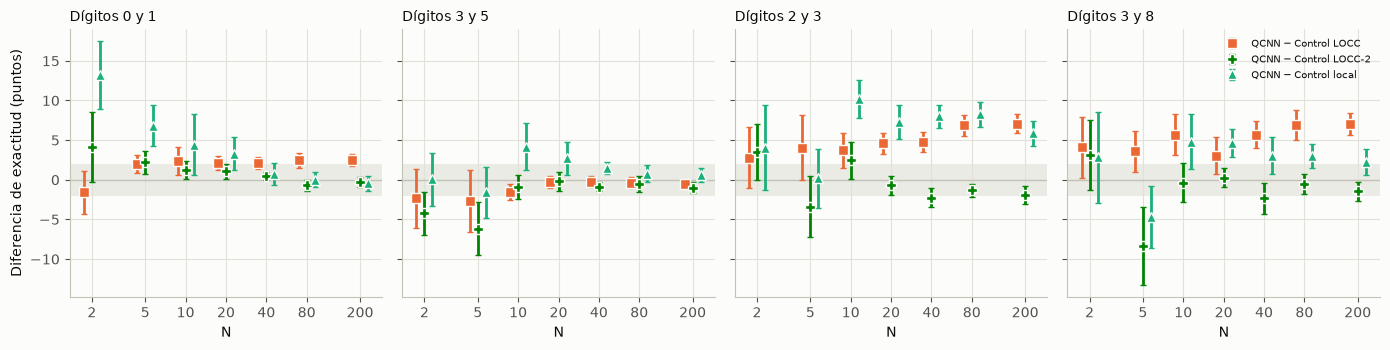

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
desplaz = {"Control LOCC": -0.06, "Control LOCC-2": 0.0, "Control local": 0.06}
for ax, par in zip(axes, PARES):
    d = dif_f2[dif_f2.par == nombre_par(par)]
    ax.axhspan(-100 * MARGEN_EQ, 100 * MARGEN_EQ, color="#e1e0d9", alpha=0.6, lw=0)
    ax.axhline(0, color="#c3c2b7", lw=1)
    for control in CONTROLES:
        dc = d[d.control == control]
        x = np.log10(dc.N) + desplaz[control]
        ax.errorbar(x, 100 * dc.media, yerr=100 * dc.ic, color=COLOR[control], marker=MARCA[control], ls="",
                    capsize=2.5, label=f"QCNN − {control}", markeredgecolor="#fcfcfb", markeredgewidth=1)
    ax.set_xticks(np.log10(TAMANOS_F), TAMANOS_F); ax.minorticks_off()
    ax.set_title(f"Dígitos {nombre_par(par)}", loc="left", fontsize=10); ax.set_xlabel("N")
axes[0].set_ylabel("Diferencia de exactitud (puntos)")
axes[-1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout(); plt.show()

### 9.3 Ajuste al entrenamiento y convergencia

Una diferencia en prueba puede venir de que un modelo generaliza peor o de que no logra ajustar sus propios datos. Para separarlo miro la exactitud de entrenamiento con $N = 200$, donde ningún modelo puede memorizar, y el cambio relativo de la pérdida en el último 10% de las épocas.

In [36]:
d = f2[(f2.n_train == 200) & f2.modelo.isin(CUANTICOS)]
ajuste = pd.DataFrame({
    "Exactitud de entrenamiento": d.groupby(["par", "modelo"]).train_acc.mean().unstack().reindex(columns=CUANTICOS).round(3).stack(),
    "Exactitud de prueba": d.groupby(["par", "modelo"]).test_acc.mean().unstack().reindex(columns=CUANTICOS).round(3).stack(),
}).unstack()
print("N = 200: exactitud media de entrenamiento y de prueba")
display(ajuste)

conv = (f2[f2.modelo.isin(CUANTICOS)].groupby(["modelo"])
        .cambio_ultimo_10pct.describe(percentiles=[0.5, 0.9])[["mean", "50%", "90%", "min"]] * 100).round(2)
conv.columns = ["Media (%)", "Mediana (%)", "Percentil 90 (%)", "Mínimo (%)"]
print("Cambio relativo de la pérdida de entrenamiento entre las épocas 180 y 200 (negativo = sigue bajando)")
display(conv.reindex(CUANTICOS))

N = 200: exactitud media de entrenamiento y de prueba


Exactitud de entrenamiento                                            \
modelo                       QCNN Control LOCC Control LOCC-2 Control local   
par                                                                           
0 y 1                       0.992        0.966          0.998         0.997   
2 y 3                       0.979        0.907          0.995         0.920   
3 y 5                       0.981        0.979          0.993         0.980   
3 y 8                       0.962        0.910          0.988         0.950   

       Exactitud de prueba                                            
modelo                QCNN Control LOCC Control LOCC-2 Control local  
par                                                                   
0 y 1                0.991        0.965          0.994         0.995  
2 y 3                0.970        0.899          0.989         0.911  
3 y 5                0.976        0.981          0.986         0.970  
3 y 8                0.959        0.889          0.974         0.937

Cambio relativo de la pérdida de entrenamiento entre las épocas 180 y 200 (negativo = sigue bajando)


,Media (%),Mediana (%),Percentil 90 (%),Mínimo (%)
modelo,,,,
QCNN,-0.44,-0.19,-0.01,-13.41
Control LOCC,-0.27,-0.03,-0.00,-10.84
Control LOCC-2,-12.27,-12.59,-8.66,-32.81
Control local,-9.84,-11.05,-3.57,-18.12


### Lectura del experimento 2

1. **El control LOCC-2 nunca queda significativamente bajo la QCNN.** En las 28 combinaciones de par y tamaño, después de la corrección de Holm, la QCNN no supera al LOCC-2 en ninguna. Son equivalentes dentro de ±2 puntos en 10, el LOCC-2 es mejor en una (dígitos 2 y 3, $N = 40$: 98.0% contra 95.8%) y el resto no es concluyente, casi siempre con $N \le 10$, donde los intervalos son de 3 a 5 puntos. Con $N = 200$, el LOCC-2 obtiene 99.4%, 98.6%, 98.9% y 97.4% en los cuatro pares; la QCNN, 99.1%, 97.6%, 97.0% y 95.9%.
2. **El control LOCC original sí queda abajo, pero por su diseño.** La QCNN lo supera en 12 de 28 combinaciones, por 5 a 7 puntos en los pares 2 y 3, y 3 y 8, y por 2 a 3 puntos en 0 y 1. Con $N = 200$ no logra ajustar ni sus imágenes de entrenamiento (90.7%, 91.0% y 96.6% en esos tres pares), mientras el LOCC-2, que tampoco entrelaza, las ajusta al 98.8% o más. La única diferencia entre los dos controles es la lectura: el LOCC comprime los qubits 0 y 4 con un tercer *pooling*, y el LOCC-2 los mide a ambos. El déficit que el avance vio en los dígitos 0 y 1 es de ese diseño, no de la falta de entrelazamiento.
3. **El control local queda bajo la QCNN donde la información de un cuerpo no alcanza.** En los dígitos 2 y 3 la QCNN lo supera por 6 a 10 puntos desde $N = 10$, y su versión convexa ("Lineal sobre un cuerpo") también se queda en 85% a 93%. En 0 y 1 y en 3 y 5, donde la información de un cuerpo basta, el control local alcanza a la QCNN con 80 imágenes o más.
4. **La regresión logística sobre los píxeles es el mejor modelo desde 20 imágenes en los cuatro pares**, o empata con el mejor (en 2 y 3 con $N = 40$, 97.9% contra 98.0% del LOCC-2). Con $N = 200$ obtiene entre 98.9% y 100%.
5. **Con 2 a 5 imágenes no hay conclusiones.** Los intervalos son de 3 a 6 puntos y el orden de los modelos cambia de un par a otro.
6. **Convergencia.** La QCNN y el control LOCC convergieron (cambio mediano de la pérdida de −0.19% y −0.03% en las últimas 20 épocas). El control LOCC-2 y el local siguen bajando su pérdida alrededor de 12%, porque crecen los pesos de su salida logística; su exactitud de entrenamiento ya está en 98% a 99.8% con $N = 200$, así que más épocas los vuelven más seguros, pero difícilmente más exactos.

La lectura conjunta es que, en esta QCNN y con estos datos, el entrelazamiento no es lo que separa a la QCNN de sus controles. Lo que importa es que la información de los dos qubits finales llegue a la salida: con mediciones y procesamiento clásico basta.

## 10. Experimento 3: entrelazamiento graduado y entrelazamiento generado

Los controles quitan el entrelazamiento de golpe y cambian a la vez otras piezas (la capa densa, la lectura). Este experimento hace dos cosas complementarias sobre la QCNN misma:

1. **Barrido de $\lambda$.** Multiplico los ángulos de las compuertas $R_{XX}R_{YY}R_{ZZ}$ de las dos convoluciones por $\lambda \in \{0, 0.25, 0.5, 0.75, 1\}$ y entreno cada versión con el mismo protocolo del experimento 2. Con $\lambda = 1$ es la QCNN; con $\lambda = 0$ las convoluciones son locales. La capa densa $SU(4)$ se mantiene en todas, porque es la que lleva la información del qubit 4 a la lectura: quitarla repetiría el error del piloto. El barrido responde si el aporte de las convoluciones entrelazantes es gradual, tiene un umbral o no existe.
2. **Entrelazamiento generado.** Mido el estado puro justo antes del primer *pooling* (codificación más primera convolución) con dos medidas:
   - la medida de Meyer-Wallach, $Q = 2\big(1 - \tfrac{1}{n}\sum_i \mathrm{Tr}\,\rho_i^2\big)$, que vale 0 en un estado producto y 1 en el máximo de entrelazamiento de cada qubit con el resto;
   - la entropía de von Neumann entre los qubits de fila (0 a 2) y los de columna (3 a 5), en bits.

   La diferencia entre el estado después de la convolución y la imagen codificada es el entrelazamiento que agrega el circuito. Con $\lambda = 0$ la convolución es local y esa diferencia es exactamente 0.

Corro el barrido en los dos pares donde la QCNN mostró más ventaja sobre los controles en el experimento 2, con $N \in \{10, 40, 200\}$ y 20 repeticiones. El caso $\lambda = 1$ son las QCNN ya entrenadas en el experimento 2 (mismas semillas).

In [37]:
ESCALAS_LAMBDA = {"QCNN λ=0": 0.0, "QCNN λ=0.25": 0.25, "QCNN λ=0.5": 0.5, "QCNN λ=0.75": 0.75}


def hacer_qcnn(escala):
    @qml.qnode(DEV)
    def circuito(th, x):
        qml.AmplitudeEmbedding(x, wires=range(NQ))
        w = list(range(NQ))
        capa_conv(th[0:15], w, primera=True, escala=escala)
        capa_pooling(th[15:18], w)
        w = w[::2]
        capa_conv(th[18:27], w, primera=False, escala=escala)
        capa_pooling(th[27:30], w)
        w = w[::2]
        qml.ArbitraryUnitary(th[30:45], wires=w)
        return qml.probs(wires=0)
    return lambda th, x: circuito(th, x)[1]


for nombre, escala in ESCALAS_LAMBDA.items():
    registrar(nombre, hacer_qcnn(escala), 45)

# λ = 1 debe reproducir la QCNN exactamente
th = MODELOS["QCNN"]["init"](0)
print("Máx |p(λ=1) − p(QCNN)|:", float(jnp.abs(jax.vmap(hacer_qcnn(1.0), in_axes=(None, 0))(th, jnp.asarray(X35[:20]))
                                             - MODELOS["QCNN"]["pv"](th, jnp.asarray(X35[:20]))).max()))

Máx |p(λ=1) − p(QCNN)|: 2.220446049250313e-16


In [38]:
# Los dos pares con mayor ventaja media de la QCNN sobre el control LOCC (N ≥ 20) en el experimento 2.
ventaja = (dif_f2[(dif_f2.control == "Control LOCC") & (dif_f2.N >= 20)].groupby("par").media.mean().sort_values())
PARES_LAMBDA = [tuple(int(c) for c in p.split(" y ")) for p in ventaja.index[-2:][::-1]]
TAMANOS_LAMBDA = [10, 40, 200]
print("Ventaja media QCNN − LOCC con N ≥ 20 (puntos):", (100 * ventaja).round(2).to_dict())
print("Pares del barrido:", PARES_LAMBDA)

f3 = pd.concat([correr_ablacion(par, modelos=list(ESCALAS_LAMBDA), tamanos=TAMANOS_LAMBDA, etiqueta="f3")
                for par in PARES_LAMBDA], ignore_index=True)
f3 = pd.concat([f3, f2[f2.par.isin([nombre_par(p) for p in PARES_LAMBDA]) & f2.n_train.isin(TAMANOS_LAMBDA)
                       & f2.modelo.isin(["QCNN", "Control LOCC"])]], ignore_index=True)
f3["lambda"] = f3.modelo.map({**ESCALAS_LAMBDA, "QCNN": 1.0})

Ventaja media QCNN − LOCC con N ≥ 20 (puntos): {'3 y 5': -0.35, '0 y 1': 2.31, '3 y 8': 5.68, '2 y 3': 5.81}
Pares del barrido: [(2, 3), (3, 8)]


In [39]:
_ESTADOS = {}


def estados_tras_conv1(th, X, escala):
    # Estado puro de 6 qubits después de la codificación y la primera convolución (antes del primer pooling).
    if escala not in _ESTADOS:
        @qml.qnode(DEV)
        def circ(th, x):
            qml.AmplitudeEmbedding(x, wires=range(NQ))
            capa_conv(th[0:15], list(range(NQ)), primera=True, escala=escala)
            return qml.state()
        _ESTADOS[escala] = jax.jit(jax.vmap(circ, in_axes=(None, 0)))
    return np.asarray(_ESTADOS[escala](jnp.asarray(th), jnp.asarray(X)))


def meyer_wallach(psi):
    # psi: (B, 64). Q = 2 (1 − media de la pureza de cada qubit).
    T = psi.reshape(len(psi), *[2] * NQ)
    pureza = 0
    for q in range(NQ):
        A = np.moveaxis(T, q + 1, 1).reshape(len(psi), 2, -1)
        rho = np.einsum("bik,bjk->bij", A, A.conj())
        pureza = pureza + np.sum(np.abs(rho) ** 2, axis=(1, 2))
    return 2 * (1 - pureza / NQ)


def entropia_filas_columnas(psi):
    s = np.linalg.svd(psi.reshape(len(psi), 8, 8), compute_uv=False) ** 2
    return -np.sum(np.where(s > 1e-15, s * np.log2(np.where(s > 1e-15, s, 1)), 0), axis=1)


archivo_ent = DIR_RES / "f3_entrelazamiento.csv"
if archivo_ent.exists() and not RECALCULAR:
    ent = pd.read_csv(archivo_ent)
else:
    filas = []
    for par in PARES_LAMBDA:
        params = {**dict(np.load(DIR_RES / f"f3_parametros_{par[0]}{par[1]}.npz")),
                  **{k: v for k, v in np.load(DIR_RES / f"f2_parametros_{par[0]}{par[1]}.npz").items() if k.startswith("QCNN|")}}
        for n in TAMANOS_LAMBDA:
            _, Xte, _, _ = particiones_lote(par, n, REPS_F)
            for nombre, lam in {**ESCALAS_LAMBDA, "QCNN": 1.0}.items():
                TH = params[f"{nombre}|{n}"]
                for rep in range(REPS_F):
                    psi0 = Xte[rep].astype(complex)
                    psi1 = estados_tras_conv1(jnp.asarray(TH[rep]), Xte[rep], lam)
                    filas.append(dict(par=nombre_par(par), n_train=n, rep=rep, modelo=nombre, **{"lambda": lam},
                                      mw_imagen=meyer_wallach(psi0).mean(), mw_conv1=meyer_wallach(psi1).mean(),
                                      s_imagen=entropia_filas_columnas(psi0).mean(), s_conv1=entropia_filas_columnas(psi1).mean()))
    ent = pd.DataFrame(filas)
    ent.to_csv(archivo_ent, index=False)
ent["dmw"] = ent.mw_conv1 - ent.mw_imagen
ent["ds"] = ent.s_conv1 - ent.s_imagen

print("Entrelazamiento de la imagen codificada (media sobre las imágenes de prueba):")
display(ent[ent.modelo == "QCNN"].groupby("par")[["mw_imagen", "s_imagen"]].mean().round(3)
        .rename(columns={"mw_imagen": "Meyer-Wallach", "s_imagen": "Entropía filas|columnas (bits)"}))

Entrelazamiento de la imagen codificada (media sobre las imágenes de prueba):


,Meyer-Wallach,Entropía filas|columnas (bits)
par,,
2 y 3,0.638,1.036
3 y 8,0.621,0.960


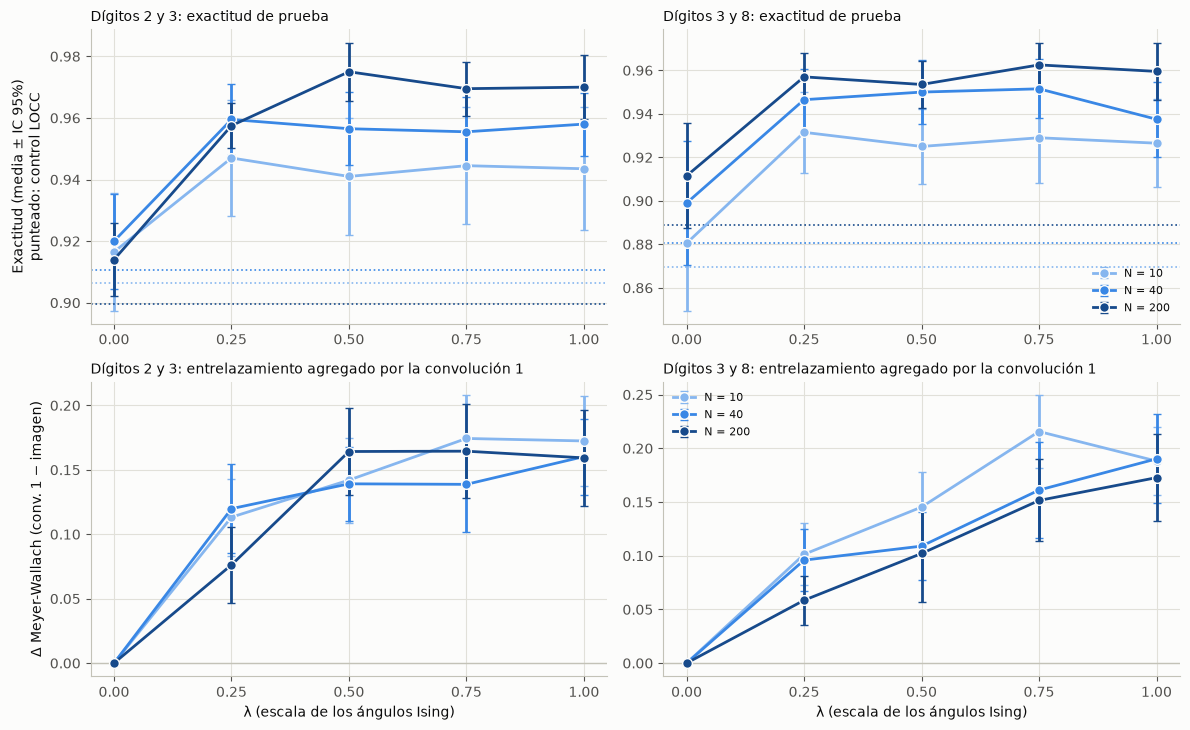

Exactitud de prueba según λ (media ± IC 95%, 20 repeticiones)


lambda                   0.0           0.25            0.5           0.75  \
par   n_train                                                               
2 y 3 10       0.916 ± 0.019  0.947 ± 0.019  0.941 ± 0.019  0.944 ± 0.019   
      40       0.920 ± 0.015  0.959 ± 0.012  0.956 ± 0.012  0.955 ± 0.011   
      200      0.914 ± 0.012  0.957 ± 0.007  0.975 ± 0.009  0.969 ± 0.009   
3 y 8 10       0.880 ± 0.031  0.931 ± 0.019  0.925 ± 0.017  0.929 ± 0.021   
      40       0.899 ± 0.029  0.946 ± 0.014  0.950 ± 0.015  0.951 ± 0.014   
      200      0.911 ± 0.024  0.957 ± 0.011  0.953 ± 0.011  0.962 ± 0.010   

lambda                   1.0   Control LOCC  
par   n_train                                
2 y 3 10       0.943 ± 0.020  0.906 ± 0.017  
      40       0.958 ± 0.010  0.910 ± 0.014  
      200      0.970 ± 0.010  0.899 ± 0.010  
3 y 8 10       0.926 ± 0.020  0.869 ± 0.021  
      40       0.937 ± 0.017  0.880 ± 0.018  
      200      0.959 ± 0.013  0.889 ± 0.016

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
COLOR_N = {10: "#86b6ef", 40: "#3987e5", 200: "#174a8b"}   # rampa azul: más oscuro = más datos
for j, par in enumerate(PARES_LAMBDA):
    d = f3[(f3.par == nombre_par(par)) & f3.modelo.ne("Control LOCC")]
    e = ent[ent.par == nombre_par(par)]
    for n in TAMANOS_LAMBDA:
        g = d[d.n_train == n].groupby("lambda").test_acc.apply(ic95).apply(pd.Series)
        axes[0, j].errorbar(g.index, g[0], yerr=g[1], color=COLOR_N[n], marker="o", capsize=3, label=f"N = {n}",
                            markeredgecolor="#fcfcfb")
        locc = f3[(f3.par == nombre_par(par)) & (f3.modelo == "Control LOCC") & (f3.n_train == n)].test_acc.mean()
        axes[0, j].axhline(locc, color=COLOR_N[n], ls=":", lw=1.2)
        g = e[e.n_train == n].groupby("lambda").dmw.apply(ic95).apply(pd.Series)
        axes[1, j].errorbar(g.index, g[0], yerr=g[1], color=COLOR_N[n], marker="o", capsize=3, label=f"N = {n}",
                            markeredgecolor="#fcfcfb")
    axes[0, j].set_title(f"Dígitos {nombre_par(par)}: exactitud de prueba", loc="left", fontsize=10)
    axes[1, j].set_title(f"Dígitos {nombre_par(par)}: entrelazamiento agregado por la convolución 1", loc="left", fontsize=10)
    axes[1, j].axhline(0, color="#c3c2b7", lw=1)
    for ax in axes[:, j]:
        ax.set_xticks(list(ESCALAS_LAMBDA.values()) + [1.0])
    axes[1, j].set_xlabel("λ (escala de los ángulos Ising)")
axes[0, 0].set_ylabel("Exactitud (media ± IC 95%)\npunteado: control LOCC")
axes[1, 0].set_ylabel("Δ Meyer-Wallach (conv. 1 − imagen)")
axes[0, 1].legend(fontsize=8, loc="lower right"); axes[1, 1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

tabla_l = (f3[f3.modelo.ne("Control LOCC")].groupby(["par", "n_train", "lambda"]).test_acc
           .apply(lambda v: "{:.3f} ± {:.3f}".format(*ic95(v))).unstack("lambda"))
tabla_l["Control LOCC"] = f3[f3.modelo == "Control LOCC"].groupby(["par", "n_train"]).test_acc.apply(
    lambda v: "{:.3f} ± {:.3f}".format(*ic95(v)))
print("Exactitud de prueba según λ (media ± IC 95%, 20 repeticiones)")
display(tabla_l)

In [41]:
# ¿Las QCNN (λ = 1) que generan más entrelazamiento clasifican mejor? Correlación de Spearman entre repeticiones.
filas = []
for par in PARES_LAMBDA:
    for n in TAMANOS_LAMBDA:
        e = ent[(ent.par == nombre_par(par)) & (ent.n_train == n) & (ent.modelo == "QCNN")].set_index("rep")
        acc = f2[(f2.par == nombre_par(par)) & (f2.n_train == n) & (f2.modelo == "QCNN")].set_index("rep").test_acc
        r = stats.spearmanr(e.dmw, acc.loc[e.index])
        filas.append({"Par": nombre_par(par), "N": n, "Δ Meyer-Wallach medio": round(e.dmw.mean(), 3),
                      "Δ entropía filas|columnas (bits)": round(e.ds.mean(), 3),
                      "Spearman ρ (Δ MW, exactitud)": round(r.statistic, 2), "p": round(r.pvalue, 3)})
display(pd.DataFrame(filas).set_index(["Par", "N"]))

Δ Meyer-Wallach medio  Δ entropía filas|columnas (bits)  \
Par   N                                                              
2 y 3 10                   0.172                             0.534   
      40                   0.160                             0.543   
      200                  0.159                             0.538   
3 y 8 10                   0.188                             0.661   
      40                   0.190                             0.610   
      200                  0.173                             0.571   

           Spearman ρ (Δ MW, exactitud)      p  
Par   N                                         
2 y 3 10                           0.43  0.061  
      40                          -0.06  0.795  
      200                          0.21  0.367  
3 y 8 10                          -0.24  0.311  
      40                          -0.02  0.929  
      200                         -0.40  0.082

### Lectura del experimento 3

1. **La imagen ya llega entrelazada.** La codificación en amplitudes de un dígito tiene una medida de Meyer-Wallach de 0.62 a 0.64 y casi 1 bit de entropía entre los qubits de fila y los de columna. La primera convolución entrenada agrega 0.16 a 0.18 en Meyer-Wallach y 0.54 a 0.61 bits.
2. **Quitar las compuertas Ising de las convoluciones cuesta 3 a 6 puntos.** Con $\lambda = 0$ la QCNN queda en 91% a 92% (2 y 3) y 88% a 91% (3 y 8), contra 93% a 97% con $\lambda = 1$. Queda 1 a 2 puntos sobre el control LOCC, que además pierde la capa densa.
3. **El efecto tiene un umbral cerca de 0.** Con $\lambda = 0.25$ la exactitud ya está a 1 o 2 puntos de la QCNN, y de 0.25 a 1 casi no cambia. El entrelazamiento agregado, en cambio, sigue creciendo: pasa de 0.09 a 0.10 con $\lambda = 0.25$ a 0.16 a 0.18 con $\lambda = 1$. La exactitud no sigue a la cantidad de entrelazamiento.
4. **Entre repeticiones tampoco hay relación.** En las QCNN entrenadas ($\lambda = 1$), la correlación de Spearman entre el entrelazamiento que genera la primera convolución y la exactitud de prueba va de −0.40 a 0.43, con signo cambiante y ningún valor $p$ bajo 0.05.

Este experimento no contradice al anterior. La QCNN con $\lambda = 0$ todavía tiene una compuerta entrelazante, la capa densa, y aun así, con 40 y 200 imágenes, queda 6 a 7.5 puntos bajo el control LOCC-2, que no tiene ninguna. Lo que distingue a los modelos que funcionan bien es cuánta información de la imagen llega a la lectura; el entrelazamiento es una de las formas de llevarla, no la única.

## 11. Experimento 4: ejecución en un computador cuántico de IBM

Todo lo anterior es simulación. Esta sección ejecuta los cuatro modelos cuánticos ya entrenados en un procesador de IBM Quantum con el plan gratuito (Open Plan, 10 minutos de QPU cada 28 días). Entrenar en hardware no cabe en ese presupuesto: una sola época con diferencias finitas y $N = 40$ son 3 640 circuitos. Lo que sí cabe es la **inferencia**: tomo los parámetros entrenados en simulación exacta y clasifico en el hardware las imágenes de prueba.

El diseño:

- **Modelos y datos.** Dígitos 3 y 5, $N = 40$, repetición 0 del experimento 2, para los cuatro modelos. Las mismas 100 imágenes de prueba para todos: 400 circuitos.
- **Circuito.** Versión con *pooling* diferido (rotaciones controladas). Es equivalente a la dinámica (sección 7.1) y evita la latencia de las mediciones intermedias en hardware. Se miden los seis qubits y cada modelo calcula su salida a partir de los conteos, igual que en simulación.
- **Ejecución.** `SamplerV2` de Qiskit IBM Runtime, 1 000 *shots* por circuito, transpilación con nivel 3 y desacoplamiento dinámico. No aplico mitigación de errores: el objetivo es ver cuánto del resultado sobrevive al hardware tal cual.
- **Tres referencias por imagen.** La probabilidad exacta (vector de estado), la de un simulador con el modelo de ruido del mismo procesador (calibración del día) y la medida en el hardware.

Con `EJECUTAR_IBM = False` el notebook lee los conteos guardados en `resultados/` y no se conecta. Para ejecutar hace falta una cuenta guardada con `QiskitRuntimeService.save_account(...)`. El identificador del trabajo se guarda apenas se envía, así que si la conexión se corta los resultados se recuperan sin volver a gastar tiempo de QPU.

In [42]:
import json

EJECUTAR_IBM = False          # True: envía el trabajo a IBM Quantum (gasta tiempo de QPU)
BACKEND_IBM = None            # nombre del procesador, o None para el menos ocupado
PAR_HW, N_HW, REP_HW, SHOTS_HW = (3, 5), 40, 0, 1000
archivo_trabajo = DIR_RES / "f4_ibm_trabajo.json"
archivo_hw = DIR_RES / "f4_ibm_conteos.json"
archivo_sim_hw = DIR_RES / "f4_simulacion_ruidosa.json"

params_hw = np.load(DIR_RES / f"f2_parametros_{PAR_HW[0]}{PAR_HW[1]}.npz")
TH_HW = {m: params_hw[f"{m}|{N_HW}"][REP_HW] for m in CUANTICOS}
_, Xte_hw, _, yte_hw = particion(*cargar_par(*PAR_HW), N_HW, REP_HW)
circuitos_hw = [circuito_qiskit(m, TH_HW[m], x) for m in CUANTICOS for x in Xte_hw]
etiquetas_hw = [(m, i) for m in CUANTICOS for i in range(len(Xte_hw))]
print(f"{len(circuitos_hw)} circuitos × {SHOTS_HW} shots = {len(circuitos_hw) * SHOTS_HW:,} ejecuciones")


def conectar_ibm():
    from qiskit_ibm_runtime import QiskitRuntimeService
    servicio = QiskitRuntimeService()
    if BACKEND_IBM:
        return servicio, servicio.backend(BACKEND_IBM)
    return servicio, servicio.least_busy(operational=True, simulator=False, min_num_qubits=NQ)


def conteos_de_resultado(resultado):
    return [r.data.c.get_counts() for r in resultado]


if archivo_hw.exists():
    hw = json.loads(archivo_hw.read_text(encoding="utf-8"))
elif archivo_trabajo.exists():
    # El trabajo ya se envió: se recuperan los resultados sin volver a ejecutar.
    info = json.loads(archivo_trabajo.read_text(encoding="utf-8"))
    servicio, _ = conectar_ibm()
    trabajo = servicio.job(info["job_id"])
    print("Estado del trabajo", info["job_id"], ":", trabajo.status())
    hw = dict(info, conteos=conteos_de_resultado(trabajo.result()), uso=trabajo.usage())
    archivo_hw.write_text(json.dumps(hw), encoding="utf-8")
elif EJECUTAR_IBM:
    from qiskit_ibm_runtime import SamplerV2
    servicio, backend = conectar_ibm()
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=0)
    isa_hw = pm.run(circuitos_hw)
    sampler = SamplerV2(mode=backend)
    sampler.options.default_shots = SHOTS_HW
    sampler.options.dynamical_decoupling.enable = True
    sampler.options.dynamical_decoupling.sequence_type = "XpXm"
    trabajo = sampler.run(isa_hw)
    info = dict(job_id=trabajo.job_id(), backend=backend.name, enviado=time.strftime("%Y-%m-%d %H:%M:%S"),
                compuertas_2q=[compuertas_2q(c) for c in isa_hw], profundidad=[c.depth() for c in isa_hw])
    archivo_trabajo.write_text(json.dumps(info), encoding="utf-8")
    print(f"Trabajo {info['job_id']} enviado a {backend.name}; esperando resultados...")
    hw = dict(info, conteos=conteos_de_resultado(trabajo.result()), uso=trabajo.usage())
    archivo_hw.write_text(json.dumps(hw), encoding="utf-8")
else:
    hw = None
    print("Sin resultados de hardware guardados y EJECUTAR_IBM = False: se omite la ejecución en IBM Quantum.")

if hw:
    print(f"Procesador: {hw['backend']} | enviado: {hw['enviado']} | tiempo de QPU usado: {hw['uso']} s")
    print(f"Compuertas de dos qubits tras transpilar: mediana {np.median(hw['compuertas_2q']):.0f} "
          f"(rango {min(hw['compuertas_2q'])}–{max(hw['compuertas_2q'])}); profundidad mediana {np.median(hw['profundidad']):.0f}")

400 circuitos × 1000 shots = 400,000 ejecuciones
Procesador: ibm_fez | enviado: 2026-11-24 10:26:03 | tiempo de QPU usado: 111 s
Compuertas de dos qubits tras transpilar: mediana 116 (rango 96–139); profundidad mediana 386


La simulación ruidosa usa el modelo de ruido del mismo procesador que corrió el trabajo, construido con `AerSimulator.from_backend` a partir de su calibración. Si no hay resultados de hardware, usa FakeMarrakesh (Heron r2) como sustituto.

In [43]:
if archivo_sim_hw.exists() and not RECALCULAR and (hw is None or
                                                    json.loads(archivo_sim_hw.read_text())["backend"] == hw["backend"]):
    sim_hw = json.loads(archivo_sim_hw.read_text(encoding="utf-8"))
else:
    if hw:
        from qiskit_ibm_runtime import QiskitRuntimeService
        backend_ref = QiskitRuntimeService().backend(hw["backend"])
    else:
        backend_ref = FakeMarrakesh()
    t0 = time.perf_counter()
    sim_ruido = AerSimulator.from_backend(backend_ref, seed_simulator=3)
    isa = generate_preset_pass_manager(optimization_level=3, backend=backend_ref, seed_transpiler=0).run(circuitos_hw)
    res = sim_ruido.run(isa, shots=SHOTS_HW).result()
    sim_hw = dict(backend=backend_ref.name, conteos=[res.get_counts(i) for i in range(len(isa))])
    archivo_sim_hw.write_text(json.dumps(sim_hw), encoding="utf-8")
    print(f"Simulación ruidosa ({backend_ref.name}): {time.perf_counter() - t0:.0f} s")

filas = []
for k, (m, i) in enumerate(etiquetas_hw):
    fila = dict(modelo=m, imagen=i, y=yte_hw[i],
                p_exacta=salida_desde_distribucion(m, TH_HW[m], distribucion_exacta(circuitos_hw[k])),
                p_simulada=salida_desde_distribucion(m, TH_HW[m], distribucion_conteos(sim_hw["conteos"][k])))
    if hw:
        fila["p_hardware"] = salida_desde_distribucion(m, TH_HW[m], distribucion_conteos(hw["conteos"][k]))
    filas.append(fila)
f4 = pd.DataFrame(filas)
fuentes = {"p_exacta": "Exacta", "p_simulada": f"Simulador ruidoso ({sim_hw['backend']})"}
if hw:
    fuentes["p_hardware"] = f"Hardware ({hw['backend']})"


def resumen_hw(d):
    out = {}
    for col, nom in fuentes.items():
        out[f"Exactitud: {nom}"] = np.mean((d[col] > 0.5) == d.y)
    for col, nom in list(fuentes.items())[1:]:
        b, a = np.polyfit(d.p_exacta, d[col], 1)
        out[f"Pendiente vs. exacta: {nom}"] = b
        out[f"Acuerdo con la exacta: {nom}"] = np.mean((d[col] > 0.5) == (d.p_exacta > 0.5))
    return pd.Series(out)


tabla_hw = f4.groupby("modelo").apply(resumen_hw).reindex(CUANTICOS)
print(f"Dígitos {nombre_par(PAR_HW)}, N = {N_HW}, repetición {REP_HW}: 100 imágenes de prueba, {SHOTS_HW} shots")
display(tabla_hw.T.round(3))

Dígitos 3 y 5, N = 40, repetición 0: 100 imágenes de prueba, 1000 shots


modelo,QCNN,Control LOCC,Control LOCC-2,Control local
Exactitud: Exacta,0.990,0.970,0.990,0.970
Exactitud: Simulador ruidoso (ibm_fez),0.980,0.970,0.990,0.940
Exactitud: Hardware (ibm_fez),0.990,0.970,0.990,0.880
Pendiente vs. exacta: Simulador ruidoso (ibm_fez),0.678,0.735,0.926,0.940
Acuerdo con la exacta: Simulador ruidoso (ibm_fez),0.990,0.980,1.000,0.970
Pendiente vs. exacta: Hardware (ibm_fez),0.531,0.605,0.913,0.843
Acuerdo con la exacta: Hardware (ibm_fez),1.000,0.980,1.000,0.890


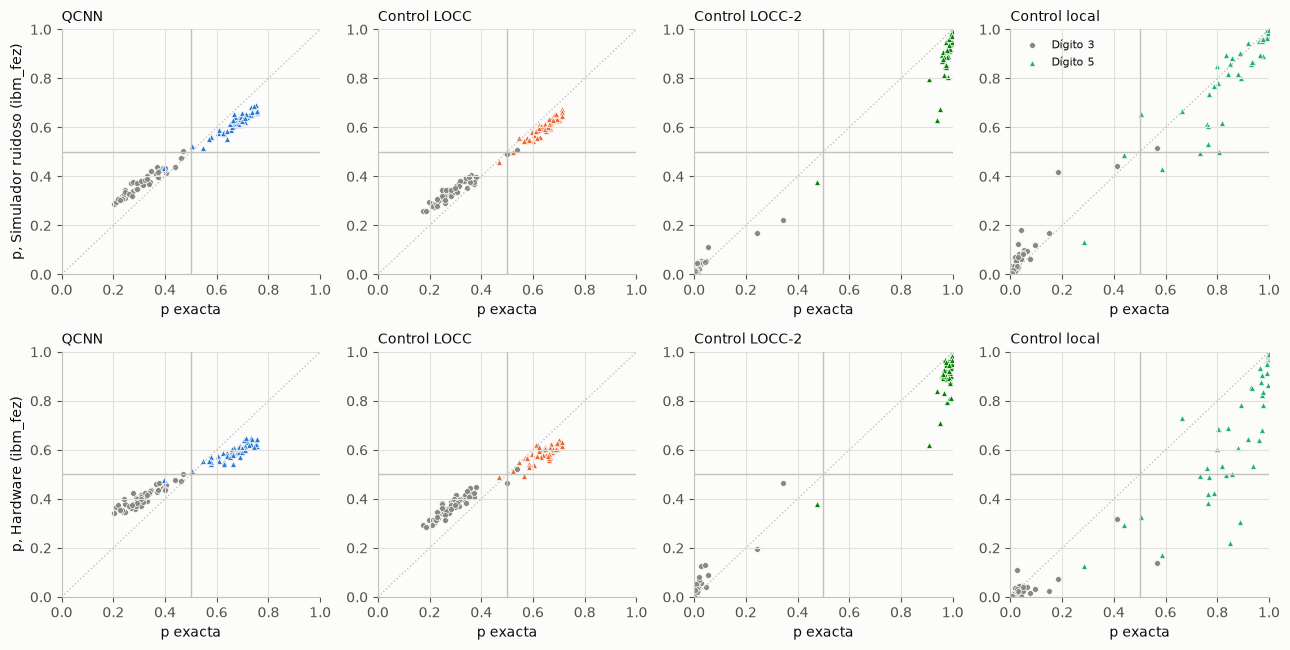

In [44]:
cols = list(fuentes)[1:]
fig, axes = plt.subplots(len(cols), 4, figsize=(13, 3.3 * len(cols)), squeeze=False)
for r, col in enumerate(cols):
    for ax, m in zip(axes[r], CUANTICOS):
        d = f4[f4.modelo == m]
        for clase, mk in [(0.0, "o"), (1.0, "^")]:
            dd = d[d.y == clase]
            ax.scatter(dd.p_exacta, dd[col], s=18, marker=mk, color=COLOR[m] if clase else GRIS,
                       edgecolor="#fcfcfb", lw=0.5, label=f"Dígito {PAR_HW[int(clase)]}")
        ax.plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls=":")
        ax.axhline(0.5, color="#c3c2b7", lw=1); ax.axvline(0.5, color="#c3c2b7", lw=1)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_title(m, loc="left", fontsize=10)
        ax.set_xlabel("p exacta")
    axes[r, 0].set_ylabel(f"p, {fuentes[col]}")
axes[0, -1].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Lectura del experimento 4

El trabajo se ejecutó el 24 de noviembre de 2026 en **ibm_fez** (Heron r2, 156 qubits) y usó 111 segundos de QPU de los 600 del plan. Cada circuito quedó con 96 a 139 compuertas de dos qubits (mediana 116) y profundidad mediana 386.

1. **La QCNN no pierde nada en hardware.** Acierta 99 de las 100 imágenes, igual que en simulación exacta, y su predicción coincide con la exacta en las 100. El control LOCC acierta 97% (97% exacto) y el LOCC-2 99% (99%). La jerarquía entre los modelos cuánticos se mantiene.
2. **Las probabilidades se contraen más de lo que predice el simulador.** La pendiente de $p_{\text{hardware}}$ contra $p_{\text{exacta}}$ es 0.53 para la QCNN y 0.61 para el control LOCC; el simulador con la calibración del mismo procesador predecía 0.68 y 0.74. El hardware tiene ruido que el modelo no captura (diafonía, deriva de la calibración, errores durante las esperas). Como la decisión es $p > 0.5$ y la contracción es casi simétrica, no cambia la clase de ninguna imagen de la QCNN.
3. **El control local es el único que se degrada: 88% contra 97% exacto.** Su salida logística multiplica cada $\langle Z_i\rangle$ por pesos de 2.7 a 8.4 en valor absoluto, porque siguió creciendo durante el entrenamiento (sección 9.3). En el hardware los $\langle Z_i\rangle$ se desplazan entre −0.07 y +0.04 respecto del simulador ruidoso, y esos pesos convierten el desplazamiento en un cambio del logit de −1.0 en promedio. Sus 12 errores en hardware son todos dígitos 5 clasificados como 3 (figura, abajo a la derecha). El LOCC-2 también tiene salida logística con pesos grandes (5 a 11), pero sus tres valores esperados se desplazan a lo más 0.02, el logit cambia solo +0.24 en promedio y casi todas sus predicciones están lejos de 0.5.

El resultado práctico es que los modelos que deciden por una sola probabilidad son robustos al ruido de este procesador, aunque esa probabilidad pierda la mitad de su distancia a 0.5, y que los modelos con una salida clásica de pesos grandes son frágiles ante desplazamientos sistemáticos de la lectura. Un entrenamiento con regularización de esos pesos, o con mitigación del error de lectura, debería recuperar parte de la diferencia; no lo probé.

### 11.1 La ablación en hardware: los cuatro pares

La ejecución anterior cubre un solo par y un solo tamaño. Con el resto del presupuesto del plan gratuito ejecuté en hardware la versión de una repetición de la tabla principal de la ablación: los 4 pares de dígitos, $N = 20$ y $N = 200$, la repetición 0 del experimento 2 y los 4 modelos cuánticos, cada uno sobre sus 100 imágenes de prueba. Son 3 200 circuitos.

- **Procesador.** ibm_kingston (Heron r2), con los mismos 6 qubits físicos para todos los circuitos, de modo que la calibración de lectura sirve para todos.
- **Shots.** Submuestreando los conteos de la sección 11, con 300 *shots* la exactitud de la QCNN y de los dos controles LOCC queda a menos de 0.6 puntos de la que dan 1 000 (el control local pierde 2.4). Envié un trabajo por par: el primero con 400 *shots*, y los siguientes con los *shots* que permitía el tiempo restante (500 y 550).
- **Calibración de lectura.** El primer trabajo incluye dos circuitos que preparan todos los qubits en 0 y todos en 1. De ahí salen, para cada qubit, la probabilidad de leer 1 cuando está en 0 y la de leer 0 cuando está en 1. Con esas matrices de confusión corrijo la distribución medida (inversa del producto tensorial de las 6 matrices de 2 × 2). Las salidas de los cuatro modelos son funciones lineales de la distribución antes de la logística, así que la corrección se aplica directamente.

La comparación principal es pareada: para cada modelo, la exactitud exacta y la de hardware sobre las mismas 100 imágenes y con los mismos parámetros. Una sola repetición no da intervalos sobre las particiones; esos están en la sección 9.

In [45]:
PARES_HW8 = [(0, 1), (3, 5), (2, 3), (3, 8)]
archivos_t8 = {par: DIR_RES / f"f5_tabla8_{par[0]}{par[1]}.json" for par in PARES_HW8}
t8 = {par: json.loads(a.read_text(encoding="utf-8")) for par, a in archivos_t8.items() if a.exists()}
print(f"Pares con resultados de hardware: {[nombre_par(p) for p in t8]}")

if t8:
    cal = t8[(0, 1)]["calibracion"]
    P0, P1 = distribucion_conteos(cal[0]), distribucion_conteos(cal[1])
    bits_ = (np.arange(2 ** NQ)[:, None] >> np.arange(NQ)) & 1
    lee1_si0 = P0 @ bits_                      # P(leer 1 | preparado 0), por qubit
    lee0_si1 = 1 - P1 @ bits_                  # P(leer 0 | preparado 1), por qubit
    display(pd.DataFrame({"P(leer 1 | 0)": lee1_si0, "P(leer 0 | 1)": lee0_si1},
                         index=[f"q{q} (físico {f})" for q, f in enumerate(t8[(0, 1)]["layout"])]).round(4))

    # Matriz de confusión de 64 × 64 como producto tensorial; el qubit q es el bit q del índice (orden de Qiskit).
    A = np.array([[1.0]])
    for q in reversed(range(NQ)):
        A = np.kron(A, np.array([[1 - lee1_si0[q], lee0_si1[q]], [lee1_si0[q], 1 - lee0_si1[q]]]))
    A_inv = np.linalg.inv(A)

    filas = []
    for par, r in t8.items():
        X, y = cargar_par(*par)
        params = np.load(DIR_RES / f"f2_parametros_{par[0]}{par[1]}.npz")
        cache_x = {n: particion(X, y, n, 0)[1] for n in (20, 200)}
        for e, conteo in zip(r["etiquetas"], r["conteos"]):
            m, n, i = e["modelo"], e["n_train"], e["imagen"]
            th = params[f"{m}|{n}"][0]
            P = distribucion_conteos(conteo)
            filas.append(dict(par=nombre_par(par), n_train=n, modelo=m, imagen=i, y=e["y"], shots=r["shots"],
                              p_exacta=salida_desde_distribucion(m, th, distribucion_exacta(circuito_qiskit(m, th, cache_x[n][i]))),
                              p_hw=salida_desde_distribucion(m, th, P),
                              p_hw_mitigada=salida_desde_distribucion(m, th, A_inv @ P)))
    f5 = pd.DataFrame(filas)
    for c in ["p_exacta", "p_hw", "p_hw_mitigada"]:
        f5["ok_" + c] = (f5[c] > 0.5) == f5.y

    acc = (f5.groupby(["par", "n_train", "modelo"])[["ok_p_exacta", "ok_p_hw", "ok_p_hw_mitigada"]].mean() * 100).round(0)
    acc.columns = ["Exacta", "Hardware", "Hardware corregido"]
    tabla8_hw = acc.unstack("modelo").swaplevel(0, 1, axis=1).reindex(columns=CUANTICOS, level=0)
    print("Exactitud (%) en las 100 imágenes de prueba de la repetición 0, ibm_kingston")
    display(tabla8_hw)

Pares con resultados de hardware: ['0 y 1', '3 y 5', '2 y 3', '3 y 8']


,P(leer 1 | 0),P(leer 0 | 1)
q0 (físico 1),0.0030,0.0232
q1 (físico 2),0.0058,0.0205
q2 (físico 3),0.0035,0.0148
q3 (físico 4),0.0068,0.0092
q4 (físico 16),0.0115,0.0122
q5 (físico 23),0.0055,0.0122


Exactitud (%) en las 100 imágenes de prueba de la repetición 0, ibm_kingston


modelo          QCNN                             Control LOCC           \
              Exacta Hardware Hardware corregido       Exacta Hardware   
par   n_train                                                            
0 y 1 20       100.0     99.0               99.0         98.0     98.0   
      200      100.0     98.0               99.0         97.0     98.0   
2 y 3 20        92.0     91.0               92.0         87.0     85.0   
      200       95.0     95.0               94.0         89.0     86.0   
3 y 5 20        94.0     93.0               90.0         98.0     93.0   
      200       98.0     91.0               94.0         99.0     98.0   
3 y 8 20        93.0     84.0               84.0         86.0     86.0   
      200       93.0     93.0               94.0         85.0     88.0   

modelo                           Control LOCC-2                              \
              Hardware corregido         Exacta Hardware Hardware corregido   
par   n_train                                                                 
0 y 1 20                    94.0          100.0    100.0              100.0   
      200                   99.0          100.0     99.0               99.0   
2 y 3 20                    86.0           94.0     87.0               87.0   
      200                   87.0           99.0     89.0               92.0   
3 y 5 20                    95.0           99.0     86.0               87.0   
      200                   98.0           99.0     95.0               95.0   
3 y 8 20                    86.0           92.0     87.0               87.0   
      200                   89.0           95.0     95.0               95.0   

modelo        Control local                              
                     Exacta Hardware Hardware corregido  
par   n_train                                            
0 y 1 20               87.0     82.0               83.0  
      200              99.0     83.0               86.0  
2 y 3 20               78.0     71.0               73.0  
      200              90.0     84.0               85.0  
3 y 5 20               97.0     92.0               92.0  
      200              94.0     87.0               87.0  
3 y 8 20               86.0     86.0               84.0  
      200              89.0     62.0               65.0

In [46]:
if t8:
    d = f5.assign(cambio_hw=100 * (f5.ok_p_hw.astype(float) - f5.ok_p_exacta),
                  cambio_mit=100 * (f5.ok_p_hw_mitigada.astype(float) - f5.ok_p_exacta))
    celdas = d.groupby(["par", "n_train", "modelo"])[["cambio_hw", "cambio_mit"]].mean().reset_index()
    resumen_hw8 = celdas.groupby("modelo").agg(
        cambio_medio=("cambio_hw", "mean"), peor=("cambio_hw", "min"),
        cambio_medio_corregido=("cambio_mit", "mean"), peor_corregido=("cambio_mit", "min")).reindex(CUANTICOS).round(1)
    resumen_hw8.columns = ["Hardware − exacta, media de las 8 celdas (pts)", "Peor celda (pts)",
                           "Corregido − exacta, media (pts)", "Peor celda corregida (pts)"]
    display(resumen_hw8)

    # QCNN contra cada control en hardware, sobre las mismas imágenes (8 celdas × 100 imágenes)
    filas = []
    for control in ["Control LOCC", "Control LOCC-2", "Control local"]:
        for col, nom in [("ok_p_exacta", "Exacta"), ("ok_p_hw", "Hardware"), ("ok_p_hw_mitigada", "Hardware corregido")]:
            a = d[d.modelo == "QCNN"].set_index(["par", "n_train", "imagen"])[col]
            b = d[d.modelo == control].set_index(["par", "n_train", "imagen"])[col]
            filas.append({"Comparación": f"QCNN − {control}", "Condición": nom,
                          "Diferencia media (pts)": round(100 * (a.astype(float) - b.astype(float)).mean(), 1),
                          "Celdas con QCNN mejor": int(((a.groupby(level=[0, 1]).mean() - b.groupby(level=[0, 1]).mean()) > 0).sum()),
                          "Celdas con control mejor": int(((a.groupby(level=[0, 1]).mean() - b.groupby(level=[0, 1]).mean()) < 0).sum())})
    display(pd.DataFrame(filas).set_index(["Comparación", "Condición"]))

    pend = (f5.groupby(["modelo"]).apply(lambda g: pd.Series({
        "Pendiente p_hw vs p_exacta": np.polyfit(g.p_exacta, g.p_hw, 1)[0],
        "Pendiente corregida": np.polyfit(g.p_exacta, g.p_hw_mitigada, 1)[0],
        "Acuerdo de clase con la exacta (%)": 100 * np.mean((g.p_hw > 0.5) == (g.p_exacta > 0.5)),
        "Acuerdo corregido (%)": 100 * np.mean((g.p_hw_mitigada > 0.5) == (g.p_exacta > 0.5))})).reindex(CUANTICOS).round(2))
    display(pend)
    uso_total = sum(r["uso"] for r in t8.values())
    print(f"Tiempo de QPU de los cuatro trabajos: {uso_total} s; shots por par: "
          f"{ {nombre_par(p): r['shots'] for p, r in t8.items()} }")

,"Hardware − exacta, media de las 8 celdas (pts)",Peor celda (pts),"Corregido − exacta, media (pts)",Peor celda corregida (pts)
modelo,,,,
QCNN,-2.6,-9.0,-2.4,-9.0
Control LOCC,-0.9,-5.0,-0.6,-4.0
Control LOCC-2,-5.0,-13.0,-4.5,-12.0
Control local,-9.1,-27.0,-8.1,-24.0


Diferencia media (pts)  \
Comparación           Condición                                    
QCNN − Control LOCC   Exacta                                 3.2   
                      Hardware                               1.5   
                      Hardware corregido                     1.5   
QCNN − Control LOCC-2 Exacta                                -1.6   
                      Hardware                               0.8   
                      Hardware corregido                     0.5   
QCNN − Control local  Exacta                                 5.6   
                      Hardware                              12.1   
                      Hardware corregido                    11.4   

                                          Celdas con QCNN mejor  \
Comparación           Condición                                   
QCNN − Control LOCC   Exacta                                  6   
                      Hardware                                4   
                      Hardware corregido                      4   
QCNN − Control LOCC-2 Exacta                                  1   
                      Hardware                                3   
                      Hardware corregido                      3   
QCNN − Control local  Exacta                                  7   
                      Hardware                                7   
                      Hardware corregido                      6   

                                          Celdas con control mejor  
Comparación           Condición                                     
QCNN − Control LOCC   Exacta                                     2  
                      Hardware                                   2  
                      Hardware corregido                         3  
QCNN − Control LOCC-2 Exacta                                     5  
                      Hardware                                   5  
                      Hardware corregido                         4  
QCNN − Control local  Exacta                                     1  
                      Hardware                                   1  
                      Hardware corregido                         1

,Pendiente p_hw vs p_exacta,Pendiente corregida,Acuerdo de clase con la exacta (%),Acuerdo corregido (%)
modelo,,,,
QCNN,0.55,0.56,95.38,96.12
Control LOCC,0.63,0.64,96.38,95.38
Control LOCC-2,0.88,0.90,94.00,94.25
Control local,0.78,0.81,85.62,87.12


Tiempo de QPU de los cuatro trabajos: 454 s; shots por par: {'0 y 1': 400, '3 y 5': 550, '2 y 3': 500, '3 y 8': 550}


### Lectura de la sección 11.1

1. **En hardware desaparece la pequeña ventaja del LOCC-2.** En estas 8 celdas, el control LOCC-2 supera a la QCNN por 1.6 puntos en promedio en simulación exacta, y en ibm_kingston queda 0.8 puntos abajo (0.5 con la corrección de lectura), aunque sigue siendo mejor en 5 de las 8 celdas. Con una repetición y 100 imágenes por celda, ninguna de las dos diferencias se distingue.
2. **Los modelos pierden exactitud en distinto grado.** La QCNN pierde 2.6 puntos en promedio (la peor celda, −9), el control LOCC 0.9, el LOCC-2 5.0 (peor celda, −13) y el control local 9.1 (peor celda, −27, en los dígitos 3 y 8 con $N = 200$). En la ejecución de la sección 11 en ibm_fez, la QCNN y el LOCC-2 no perdieron nada; ese par y ese tamaño resultaron favorables.
3. **Corregir la lectura casi no ayuda.** Mejora entre 0.2 y 1 punto, porque el error de lectura de estos 6 qubits es pequeño (0.3% a 2.3%). Casi toda la pérdida viene de otras fuentes, en primer lugar el ruido de las cerca de 115 compuertas de dos qubits de cada circuito.
4. **Los controles con salida logística pierden más.** La QCNN y el control LOCC deciden con $p > 0.5$, y una contracción simétrica hacia 0.5 no cambia esa decisión. El LOCC-2 y el control local multiplican valores esperados por pesos y suman un sesgo que no es cero (entre −6.8 y 3.2). Cuando el ruido encoge los valores esperados, el término con pesos se achica, el sesgo pesa más y la frontera de decisión se corre. Ajustando un factor de contracción por celda (0.40 a 0.85), este mecanismo predice 95.1% para el LOCC-2 y 83.9% para el control local, frente a 97.2% y 90.0% en simulación exacta y 92.2% y 80.9% en hardware: explica alrededor de 40% de la pérdida del LOCC-2 y dos tercios de la del control local. El resto viene de corrimientos que no son una simple contracción.

En hardware, entonces, comparar modelos con y sin salida clásica mezcla dos cosas: el efecto que se quiere medir y la robustez de cada lectura al ruido. Una comparación justa en hardware tendría que reajustar la salida logística con valores medidos en el mismo procesador, lo que cuesta más tiempo de QPU del que queda en el plan gratuito.

## 12. Discusión y limitaciones

**Sobre el entrelazamiento.** Los tres experimentos apuntan en la misma dirección. Un control sin ninguna compuerta entrelazante, que conserva el *pooling* por medición y lee los dos qubits finales, iguala o supera a la QCNN en los cuatro pares de dígitos. Las caídas que parecían atribuibles a quitar el entrelazamiento (el control LOCC del avance, la QCNN con $\lambda = 0$) desaparecen al cambiar cómo llega la información a la salida, y la exactitud no sigue a la cantidad de entrelazamiento ni al variar $\lambda$ ni entre repeticiones. Esto coincide con Bowles et al. (2024), que encuentran que quitar el entrelazamiento rara vez empeora a los modelos cuánticos en tareas pequeñas, y con Bermejo et al. (2026), para quienes las QCNN en tareas como esta se pueden simular clásicamente. También precisa el resultado matizado de Basilewitsch et al. (2025). Con el número de parámetros fijo no se puede comparar, porque sin compuertas de dos qubits los parámetros efectivos bajan solos (37 contra 20 o 21); la comparación por información disponible en la lectura sí es justa, y no favorece al entrelazamiento.

**Sobre la ablación como método.** El resultado más útil del trabajo puede ser metodológico. El mismo experimento, con el control LOCC del avance, habría concluido que el entrelazamiento aporta 5 a 7 puntos en dos de los cuatro pares. Con el control LOCC-2 concluye lo contrario. Un control que no deja llegar la información a la salida produce una diferencia que parece del entrelazamiento. Es la advertencia que planteó la entrega 3 con el piloto que leía un solo qubit.

**Sobre Anthony et al.** La replicación muestra que su QCNN sí aprende con muy pocas imágenes en simulación exacta (95% con $N = 2$), y que el nivel más bajo de su artículo viene de entrenar con ruido y diferencias finitas a la vez. Eso no invalida su resultado, que es experimental con un dispositivo simulado. Indica que, con el ruido de los dispositivos actuales, el cuello de botella con pocos datos es el estimador del gradiente, y que un método con menos ruido (más *shots*, la regla de desplazamiento de parámetros o mitigación de errores) debería recuperar parte de la diferencia.

**Sobre la ventaja cuántica.** No hay. Una regresión logística de 65 parámetros es el mejor modelo, o empata con el mejor, desde 20 imágenes en los cuatro pares.

**Limitaciones.**

- Una sola arquitectura (la QCNN de Anthony et al.), imágenes de 8×8 y clasificación binaria en cuatro pares. No sé si el resultado se mantiene con más qubits, más clases o imágenes más grandes.
- El control LOCC-2 combina tres valores esperados con una salida logística clásica de 4 parámetros, y la QCNN no tiene esa salida. Es parte de la diferencia de diseño entre ambos y no la separé; se podría con una QCNN que lea también los dos qubits.
- Los parámetros efectivos no se pueden igualar entre modelos con y sin entrelazamiento (sección 6.1).
- El ruido de la sección 8.2 es un modelo lineal calibrado en FakeKyiv, no la simulación completa de su entrenamiento, y supuse diferencias finitas centradas. Reproduce la forma y el nivel de sus resultados con pocos datos, pero con $N \ge 20$ queda 1 a 3 puntos por encima.
- Todos los modelos usan tasa 0.1 y 200 épocas, sin ajuste de hiperparámetros. El control LOCC-2 y el local no convergieron en pérdida, aunque su exactitud de entrenamiento ya es de 98% o más.
- Con 100 imágenes de prueba la exactitud se mide en pasos de 1 punto, y con $N \le 10$ los intervalos son de 3 a 6 puntos.
- La ejecución en hardware es solo inferencia, con una repetición por celda, 100 imágenes por celda y 400 a 1 000 *shots*. La única mitigación es la corrección del error de lectura, y la salida logística de los controles no se reajustó con datos de hardware (sección 11.1).
- No contrasté el control local con el modelo separable de `qml-benchmarks` (paso 6 del avance). Los controles se validaron por construcción (sección 6) y contra la teoría (13 parámetros efectivos del control local), no contra un código externo.

## 13. Conclusiones

Anthony et al. no publicaron su código, pero su QCNN es la del tutorial de PennyLane. Con ese código como referencia, mi implementación en PennyLane y en Qiskit reproduce el circuito hasta el error de redondeo. Simulando su backend (ruido de FakeKyiv, 4 000 *shots* y diferencias finitas) reproduce también el nivel de sus resultados con pocos datos. Ninguno de esos tres efectos alcanza por separado: la caída aparece cuando el ruido contrae el gradiente hasta dejarlo bajo el error de muestreo.

La ablación final (4 pares, 7 tamaños, 20 repeticiones) indica que en esta QCNN el entrelazamiento no es necesario para clasificar. Un control sin compuertas entrelazantes que lee los dos qubits finales no queda significativamente bajo la QCNN en ninguna de las 28 combinaciones. Lo que sí importa es que la información de toda la imagen llegue a la salida: el control que la comprime en un solo qubit queda 5 a 7 puntos abajo y ni siquiera ajusta su entrenamiento. Atenuar las compuertas Ising muestra un umbral cerca de cero y ninguna relación entre la exactitud y la cantidad de entrelazamiento generado.

En ibm_fez, la QCNN y el control LOCC-2 conservaron en hardware la exactitud que tenían en simulación. En la tabla de una repetición ejecutada en ibm_kingston, la QCNN perdió 2.6 puntos en promedio y quedó 0.8 puntos sobre el LOCC-2, una diferencia que una repetición no permite distinguir. Los controles con salida logística perdieron más porque el ruido encoge sus entradas, así que en hardware la comparación mezcla el efecto del entrelazamiento con la robustez de cada lectura.

Una regresión logística sobre los píxeles sigue siendo el mejor modelo. El aporte del trabajo no es un modelo mejor, sino una ablación bien controlada: muestra cómo un control mal diseñado puede hacer parecer útil al entrelazamiento, y que en este caso, con un control justo, no lo es.

## Referencias

- Anthony, L., Burov, A., Piro, N., Dal Peraro, M. y Javerzac, C. (2026). *Experimental evidence of generalization in quantum machine learning in small-data regime*. arXiv:2609.24666. Datos: [10.5281/zenodo.22820877](https://zenodo.org/records/22820877).
- Kottmann, K., Mantilla Calderón, L. y Weber, M. (2022, actualizado en 2026). *Generalization in QML from few training data*. Tutorial de PennyLane. https://pennylane.ai/qml/demos/tutorial_learning_few_data
- Caro, M. C. et al. (2022). Generalization in quantum machine learning from few training data. *Nature Communications* 13, 4919.
- Cong, I., Choi, S. y Lukin, M. D. (2019). Quantum convolutional neural networks. *Nature Physics* 15, 1273-1278.
- Hur, T., Kim, L. y Park, D. K. (2022). Quantum convolutional neural network for classical data classification. *Quantum Machine Intelligence* 4, 3. Código: https://github.com/takh04/QCNN
- Bowles, J., Ahmed, S. y Schuld, M. (2024). Better than classical? The subtle art of benchmarking quantum machine learning models. arXiv:2403.07059. Código: https://github.com/XanaduAI/qml-benchmarks
- Basilewitsch, D. et al. (2025). Quantum neural networks in practice. *Quantum Machine Intelligence*. arXiv:2411.19276.
- Bermejo, P. et al. (2026). Quantum convolutional neural networks are (effectively) classically simulable. *PRX Quantum* 7, 020304.
- Meyer, D. A. y Wallach, N. R. (2002). Global entanglement in multiparticle systems. *Journal of Mathematical Physics* 43, 4273-4278.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics* 6, 65-70.
- Javadi-Abhari, A. et al. (2024). Quantum computing with Qiskit. arXiv:2405.08810.
- Bergholm, V. et al. (2018). PennyLane: Automatic differentiation of hybrid quantum-classical computations. arXiv:1811.04968.